# Gercon - Exploração de Dados

Notebook de exploração inicial do banco **gercon** — Trabalho PPG informatica

Base analisada: `gercon_aps_censo.parquet`


In [1]:
#!pip install ydata-profiling
!pip install sweetviz

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#from ydata_profiling import ProfileReport
import sweetviz as sv
import os


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# Caminhos do projeto
#base_path = '/content/drive/MyDrive/01_Doutorado/Tese/banco/gercon'
#arquivo_path = f'{base_path}/gercon_aps_censo.parquet'


arquivo_path = '/content/drive/MyDrive/banco/gercon/gercon_aps_censo.parquet'

## 1. Carregamento dos dados


In [6]:
# Preview rápido só com as primeiras linhas, para checar separador/encoding/colunas
df = pd.read_parquet(arquivo_path)
df

,ANO_SOLICITACAO,IDSOLICITACAO,SITUACAOSOLICITACAO,DATA_SOLICITACAO,CORREGULADOR,DIASFILAESPERA,COMPLEXIDADE,ESPECIALIDADE,ESPECIALIDADEMAE,CID,...,densidade_hab_km2,pct_apartamentos,razao_apart_casa,pct_est_saude,pct_est_religiosos,renda_media_winsor,renda_dp,renda_cv,flag_renda_suspeita,CID_ajustada
0,2018,747495,REALIZADA,2018-02-20,AMARELO,17,MEDIA,CIRURGIA BUCOMAXILOFACIAL CEO,CIRURGIA BUCOMAXILOFACIAL,K011,...,6888.552648,15.384615,0.226488,0.086919,0.434594,2760.800651,2878.711953,104.270910,False,K01
1,2018,756290,REALIZADA,2018-02-28,AZUL,14,MEDIA,CIRURGIA BUCOMAXILOFACIAL CEO,CIRURGIA BUCOMAXILOFACIAL,K021,...,2551.101002,4.696970,0.055722,0.050505,0.606061,1659.903950,1079.210649,65.016452,False,K02
2,2018,806777,REALIZADA,2018-04-12,AZUL,1,MEDIA,CIRURGIA BUCOMAXILOFACIAL CEO,CIRURGIA BUCOMAXILOFACIAL,K011,...,1211.603418,38.096785,0.826056,0.064956,0.162390,3993.913191,4774.691182,119.549198,False,K01
3,2018,730573,REALIZADA,2018-02-01,LARANJA,5,MEDIA,PERIODONTIA,ODONTO PERIODONTIA,K061,...,958.843801,0.537934,0.006186,0.037099,0.686329,1700.161961,1716.836238,100.980746,False,K06
4,2018,744023,ENCERRADA,2018-02-16,NENHUM,0,MEDIA,PERIODONTIA,ODONTO PERIODONTIA,K051,...,1028.225601,9.515997,0.117814,0.032814,0.246103,3517.723782,4208.299792,119.631331,False,K05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1912551,2026,8595918,REALIZADA,2026-03-11,LARANJA,2,MEDIA,GINECOLOGIA COLO UTERINO,GINECOLOGIA,R876,...,6370.440655,24.552117,0.366788,0.081433,0.081433,2965.174677,2832.227650,95.516385,False,R87
1912552,2026,8253179,REALIZADA,2026-01-05,LARANJA,9,MEDIA,CARDIOLOGIA ADULTO,CARDIOLOGIA,R060,...,1611.726893,1.604707,0.019717,0.026745,0.133726,4473.202636,5843.841461,130.641107,False,R06
1912553,2026,8363864,ENCERRADA,2026-01-26,VERDE,24,MEDIA,INSUMOS PARA DIABETES,INSUMOS DIABETES,E10,...,2551.101002,4.696970,0.055722,0.050505,0.606061,1659.903950,1079.210649,65.016452,False,E10
1912554,2026,8627803,REALIZADA,2026-03-17,AZUL,1,MEDIA,GINECOLOGIA PLANEJAMENTO FAMILIAR,GINECOLOGIA,Z300,...,1994.516720,6.546023,0.081006,0.044683,0.312779,2240.150033,2128.874888,95.032692,False,Z30


In [7]:
df.info(verbose=True, memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1912556 entries, 0 to 1912555
Data columns (total 52 columns):
 #   Column                  Dtype         
---  ------                  -----         
 0   ANO_SOLICITACAO         int64         
 1   IDSOLICITACAO           category      
 2   SITUACAOSOLICITACAO     category      
 3   DATA_SOLICITACAO        datetime64[us]
 4   CORREGULADOR            category      
 5   DIASFILAESPERA          int64         
 6   COMPLEXIDADE            category      
 7   ESPECIALIDADE           category      
 8   ESPECIALIDADEMAE        category      
 9   CID                     category      
 10  IDPACIENTE              category      
 11  MUNICIPIO_RESIDENCIA    category      
 12  IDADE                   int64         
 13  CNES_SOLICITANTE        category      
 14  UNIDADESOLICITANTE      category      
 15  SITUACAOAGENDA          category      
 16  DATAHORA_CONSULTA       datetime64[us]
 17  CNESEXECUTANTE          category      
 18  UN

In [8]:
relatorio = sv.analyze(df, pairwise_analysis='off')

                                             |          | [  0%]   00:00 -> (? left)


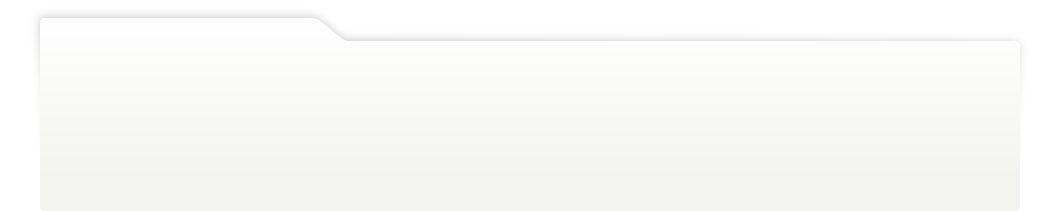
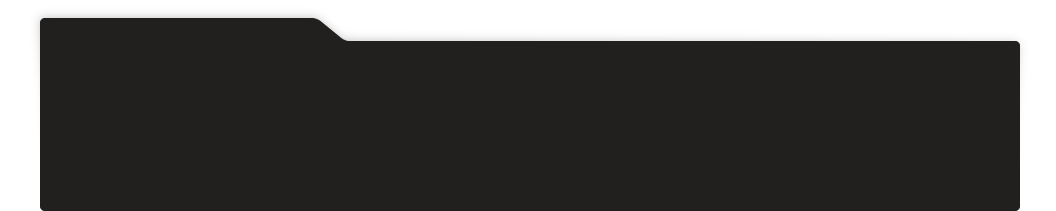
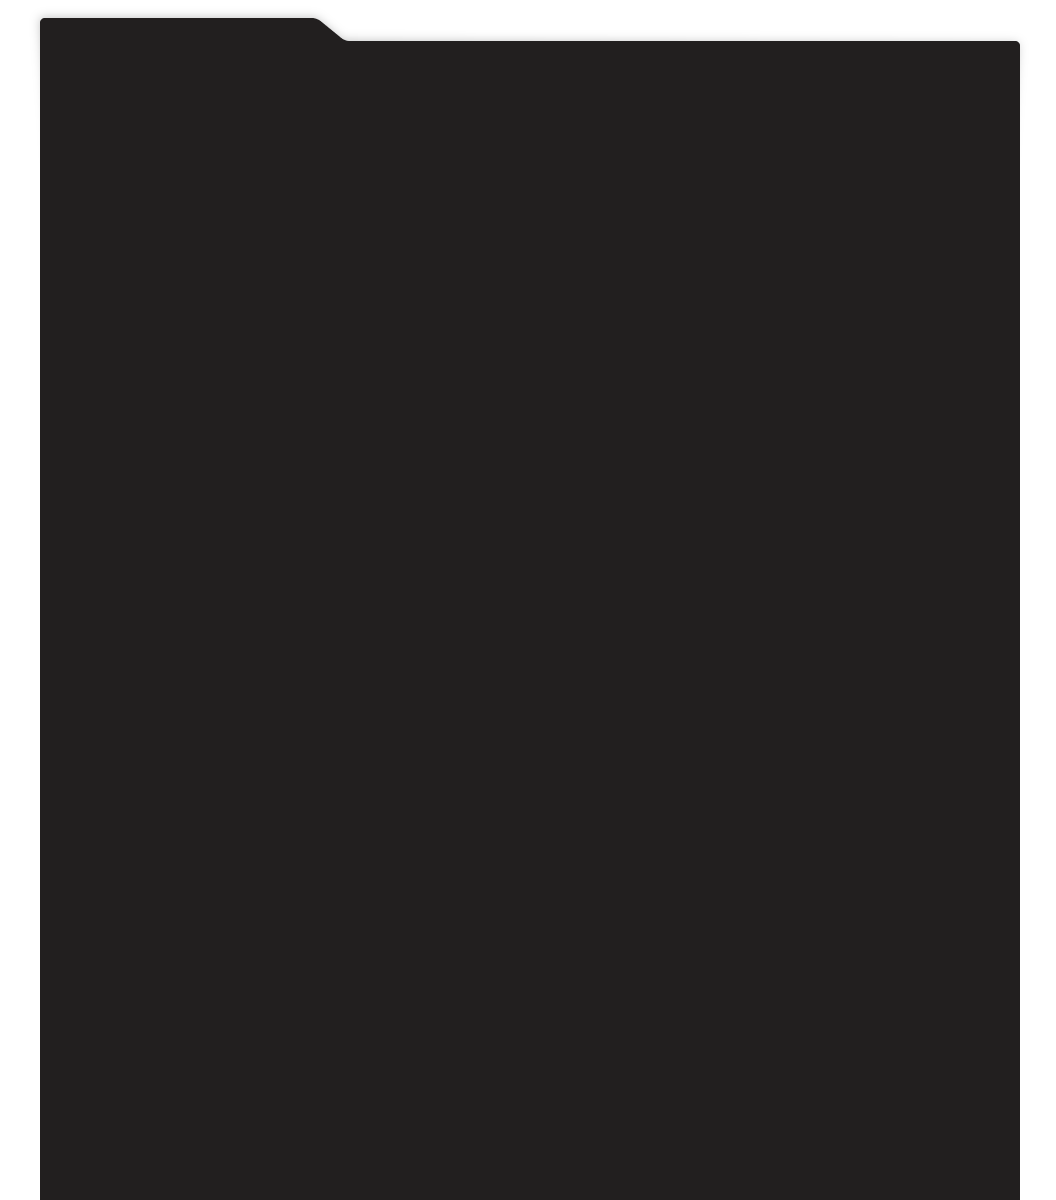
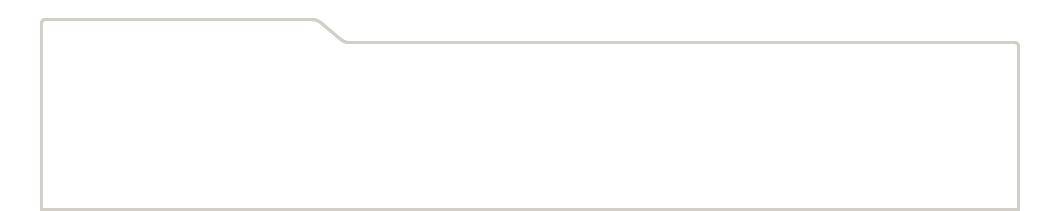
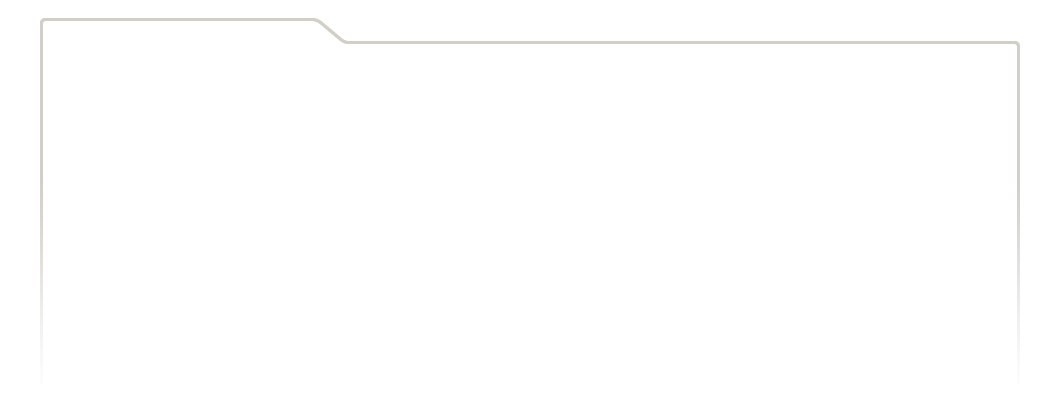
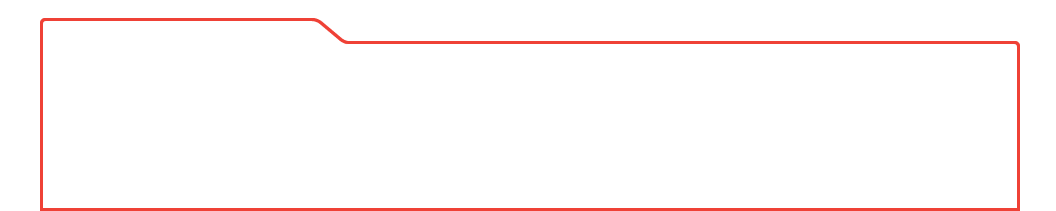
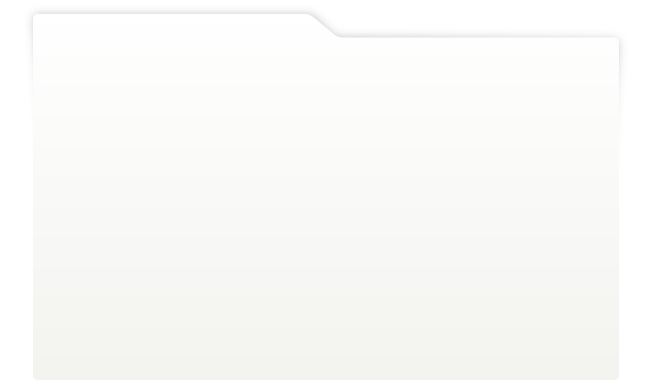
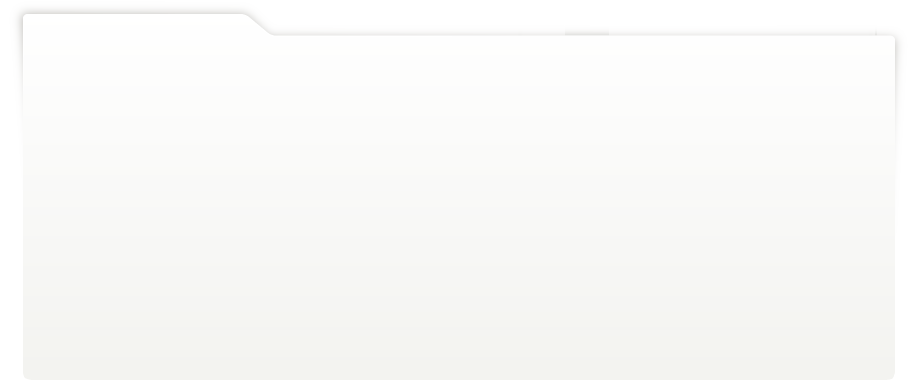
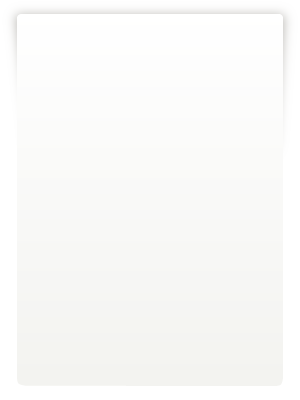
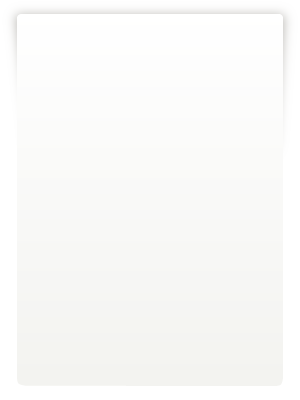
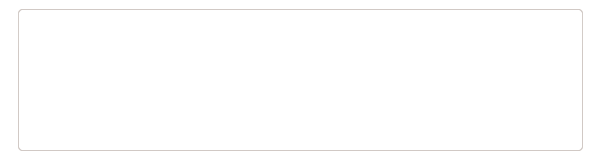
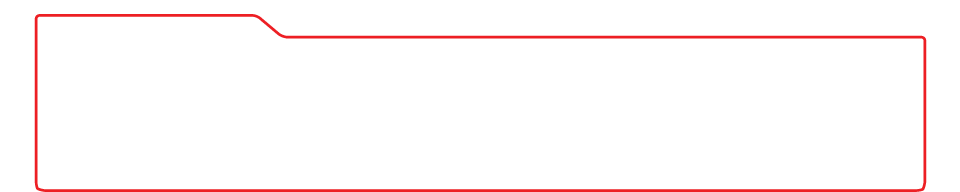
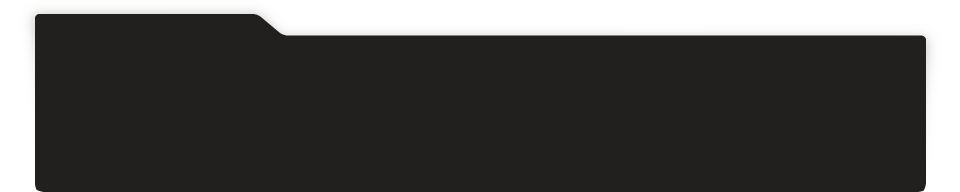
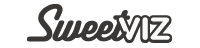
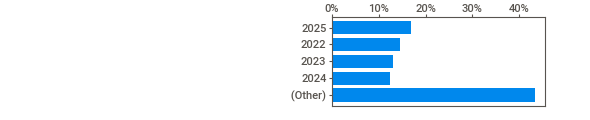
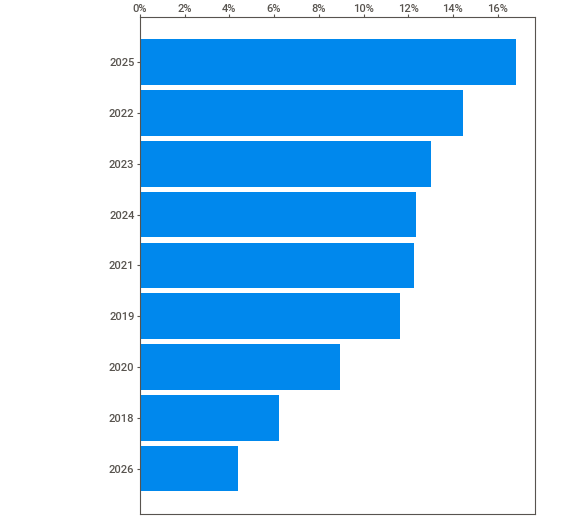
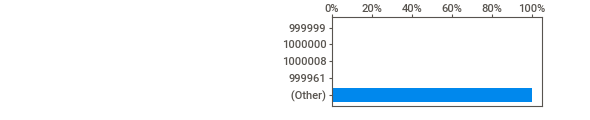
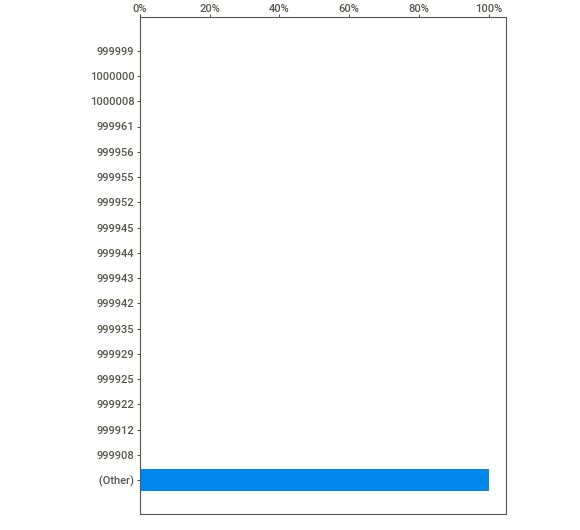
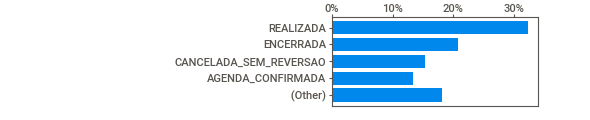
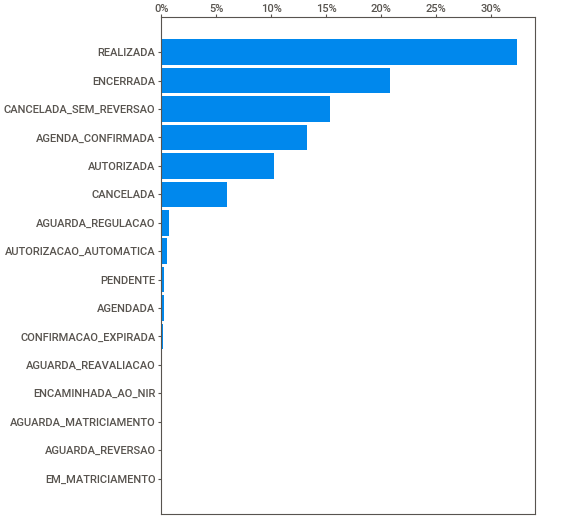
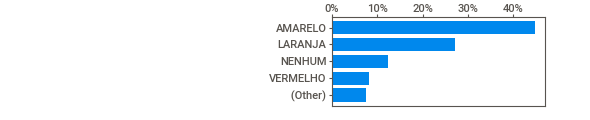
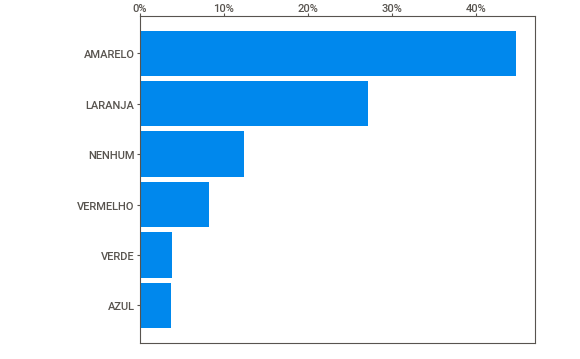
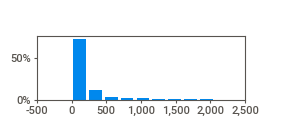
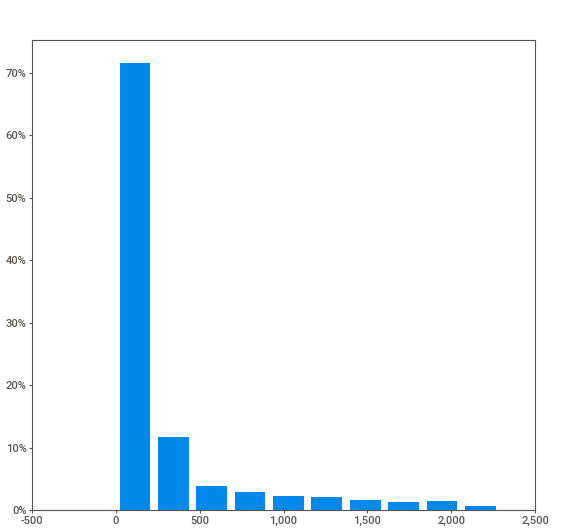
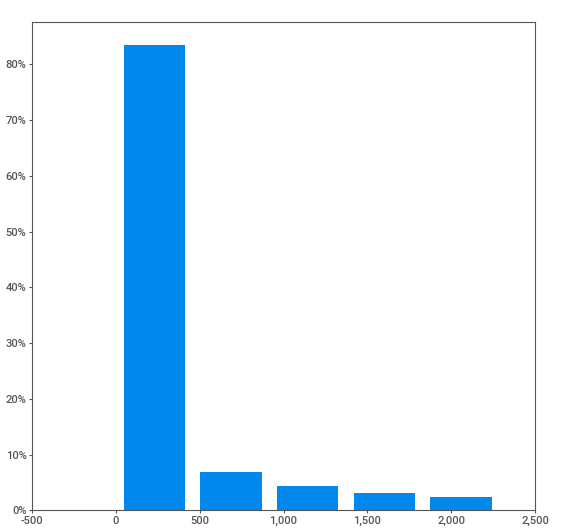
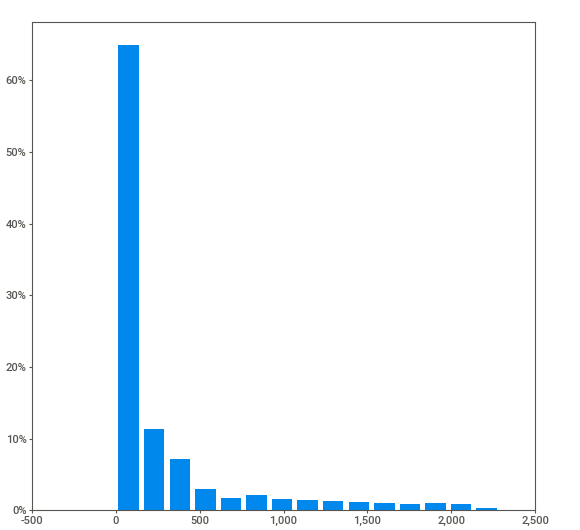
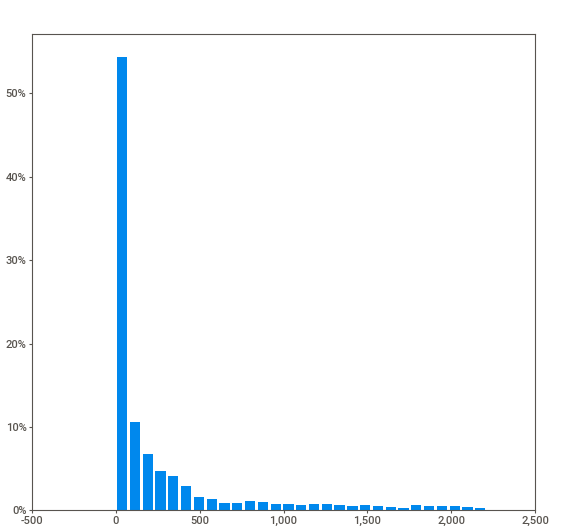
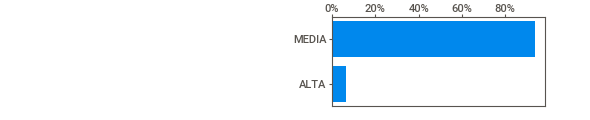
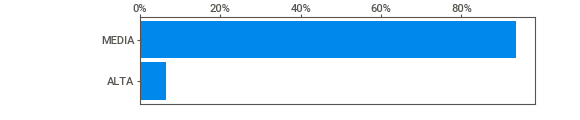
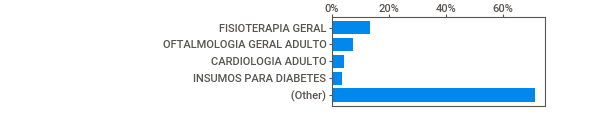
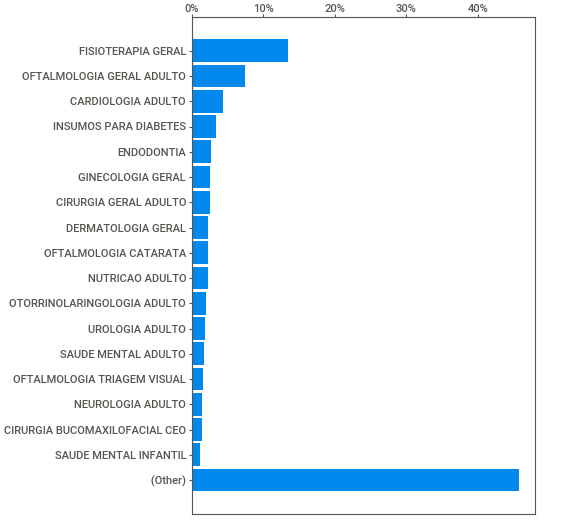
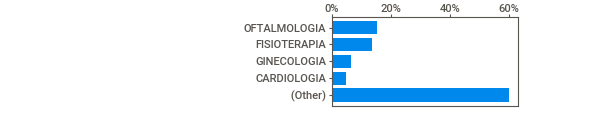
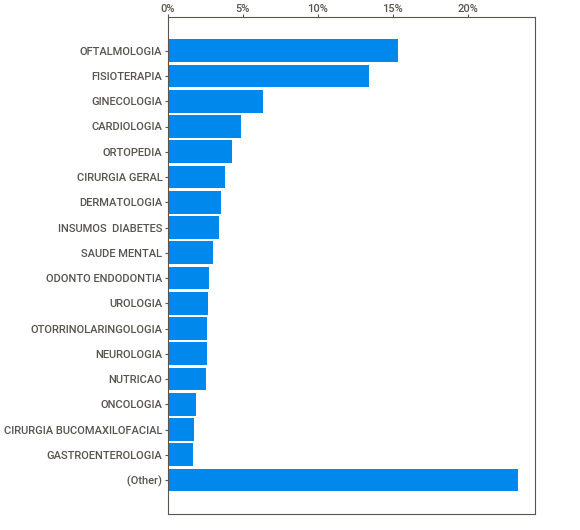
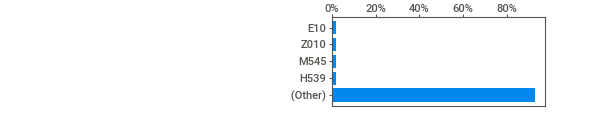
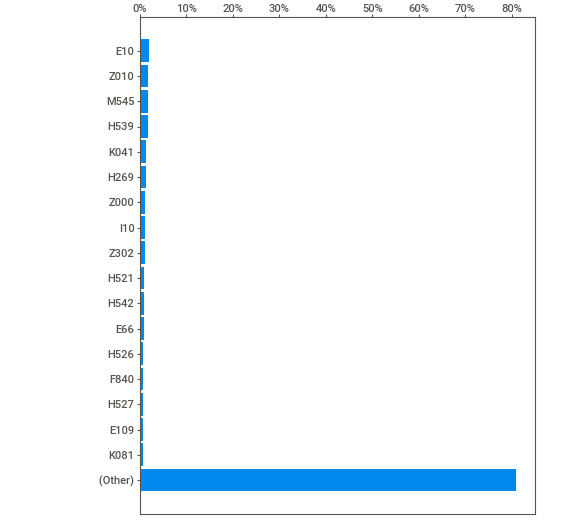
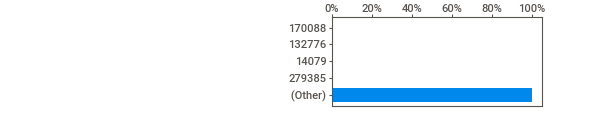
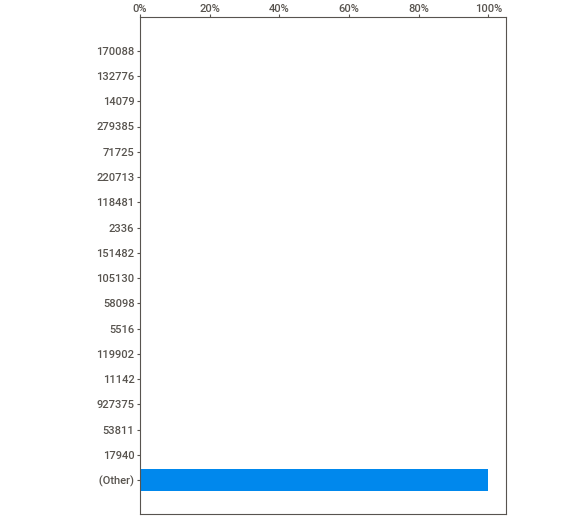
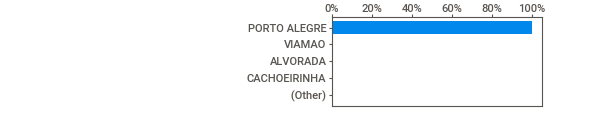
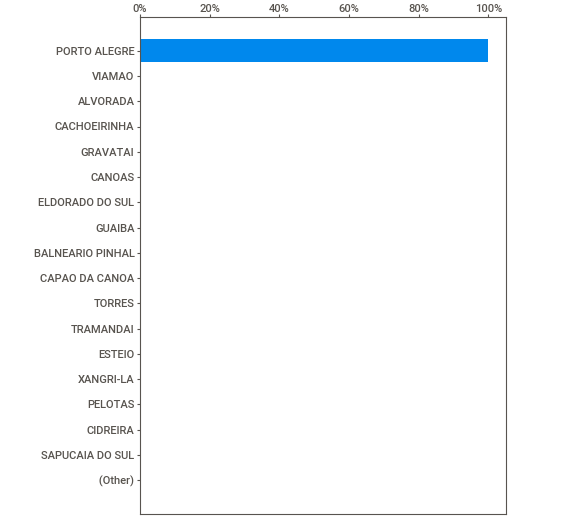
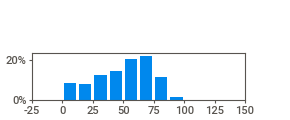
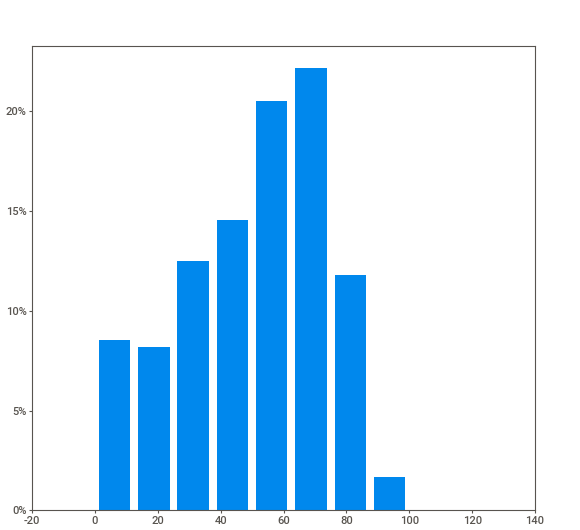
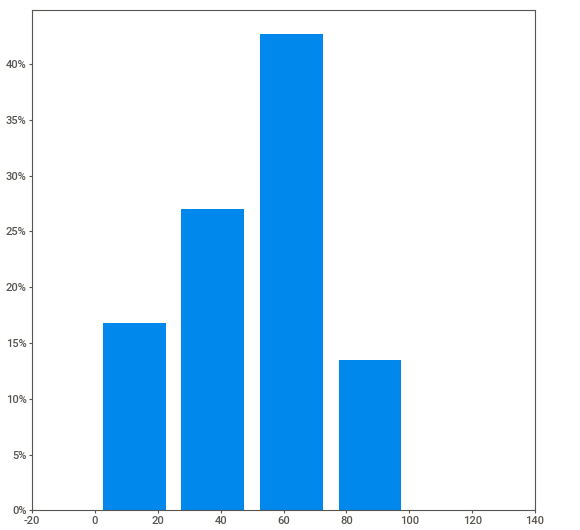
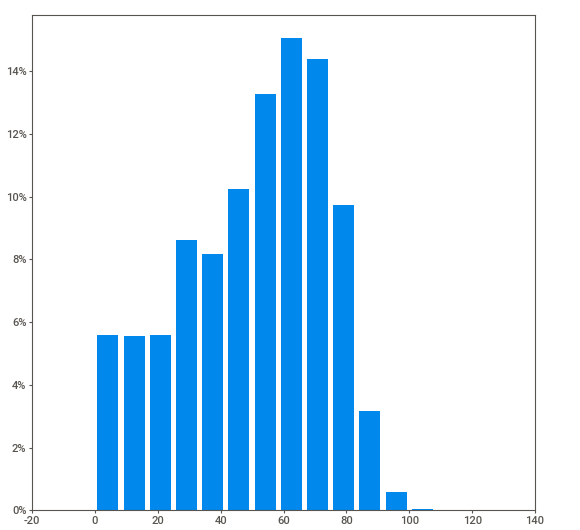
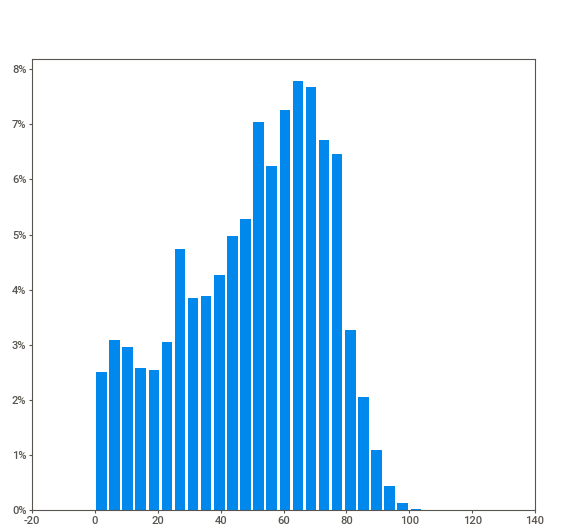
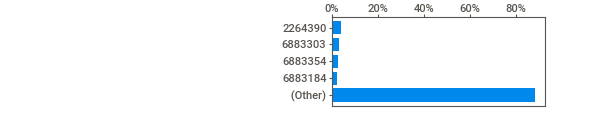
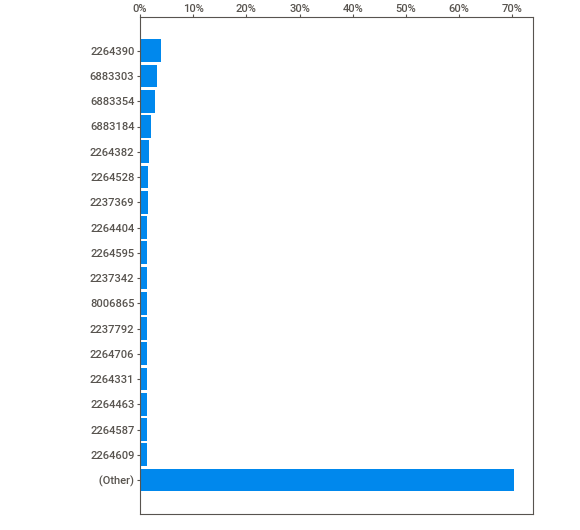
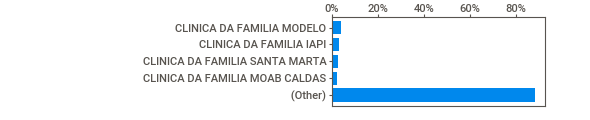
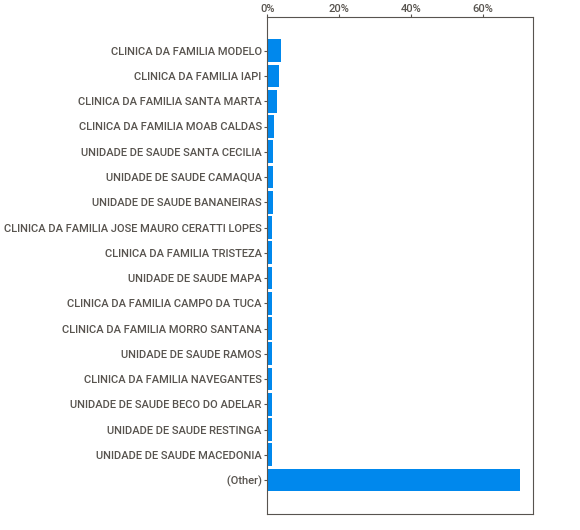
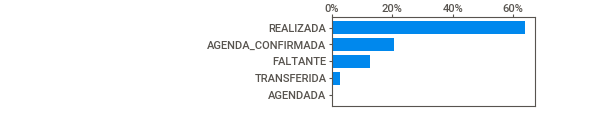
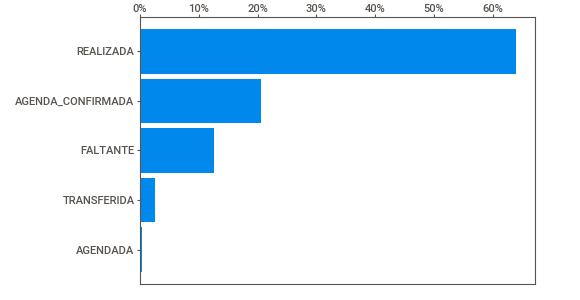
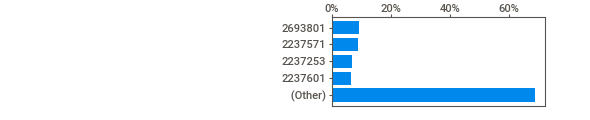
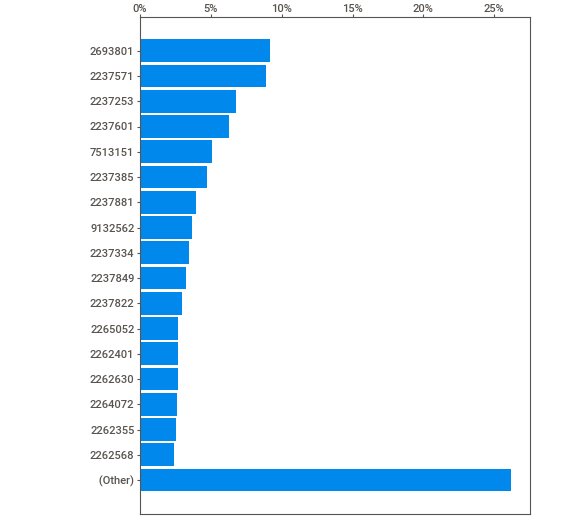
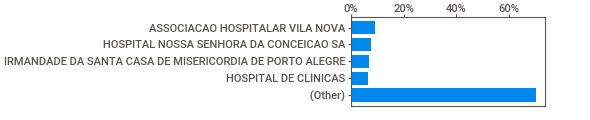
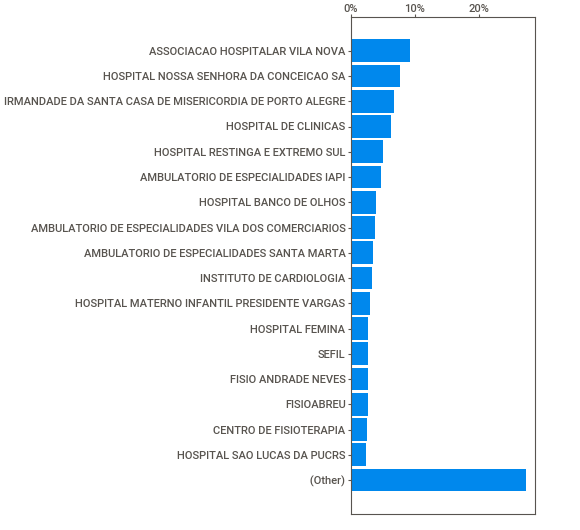
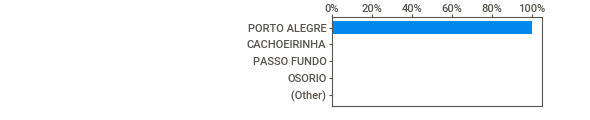
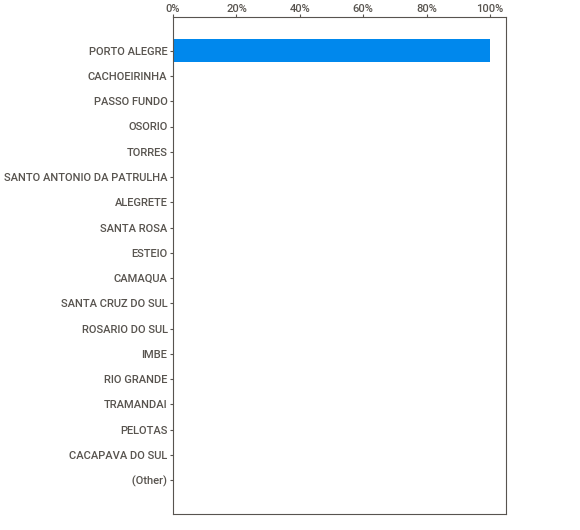
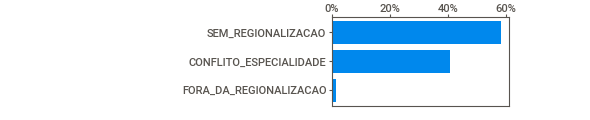
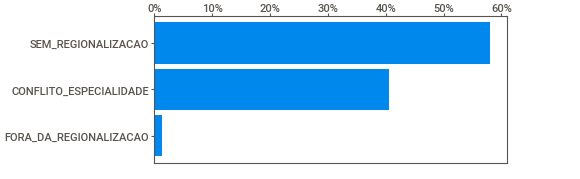
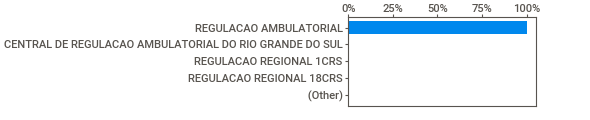
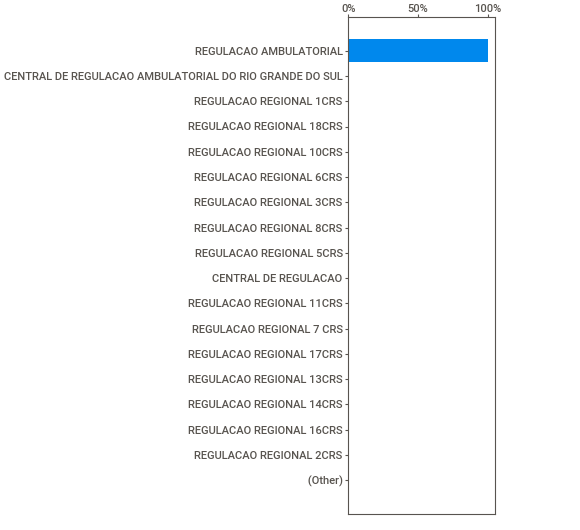
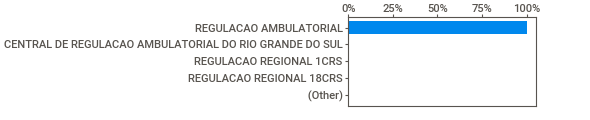
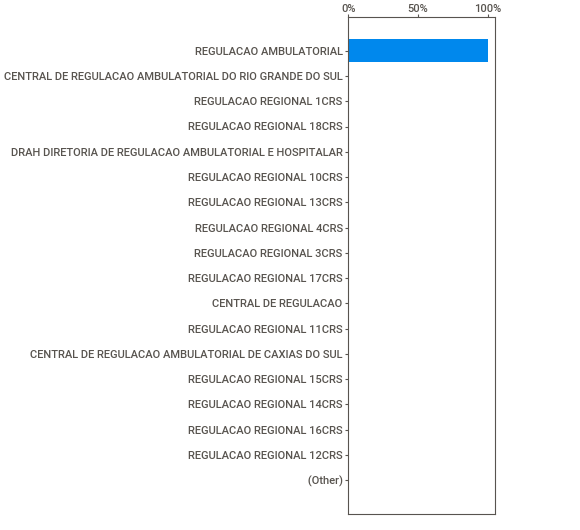
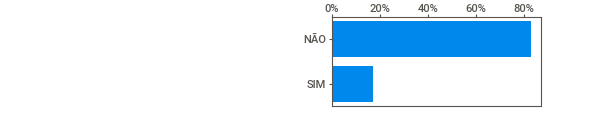
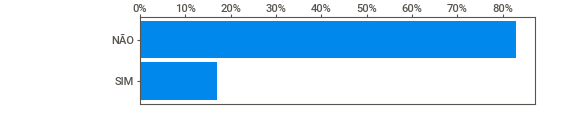
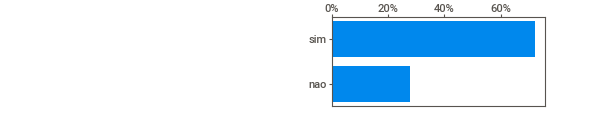
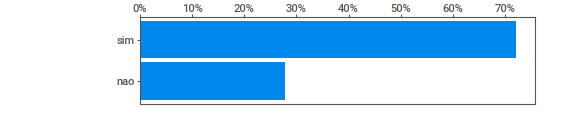
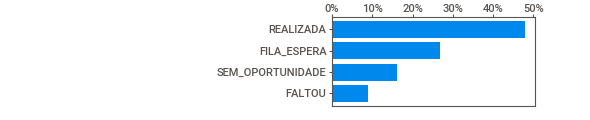
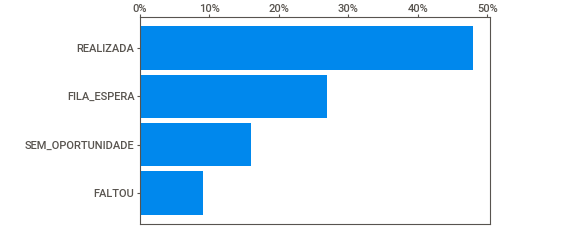
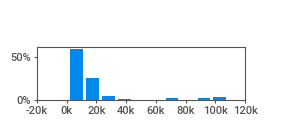
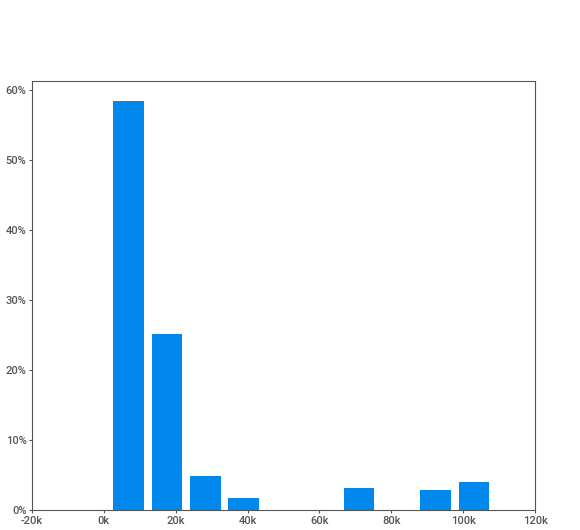
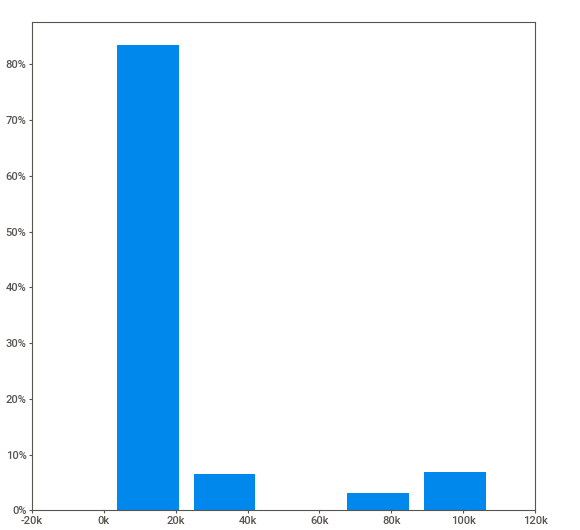
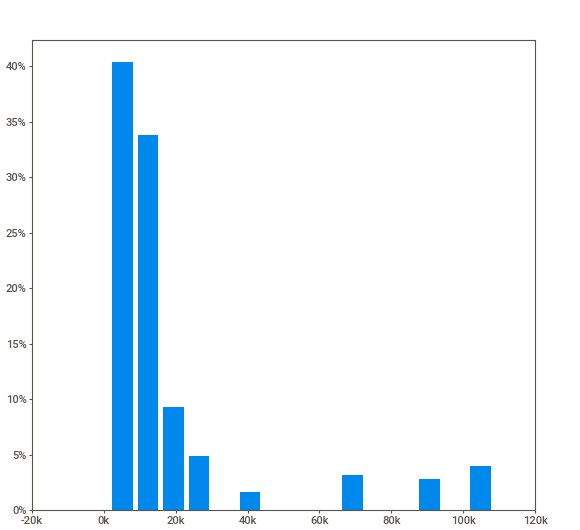
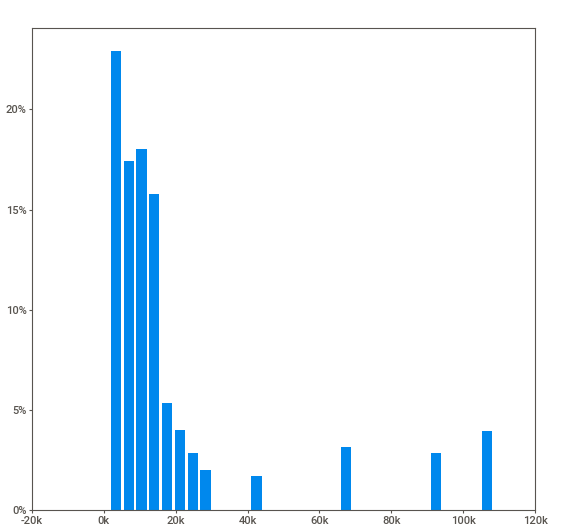
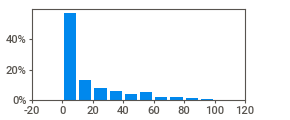
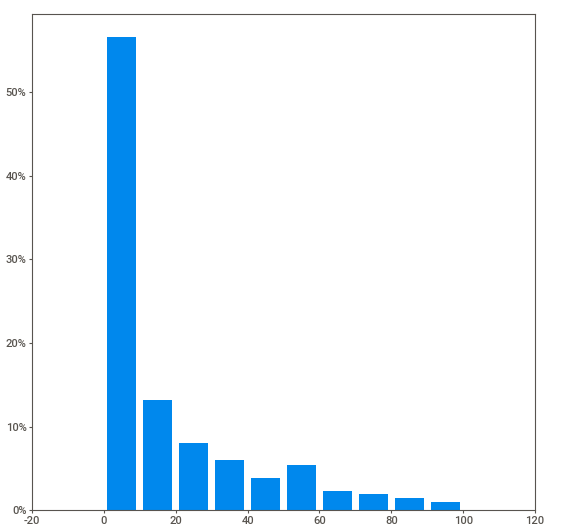
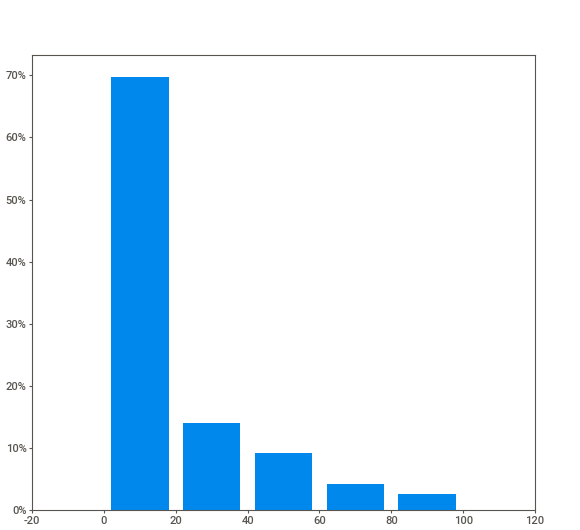
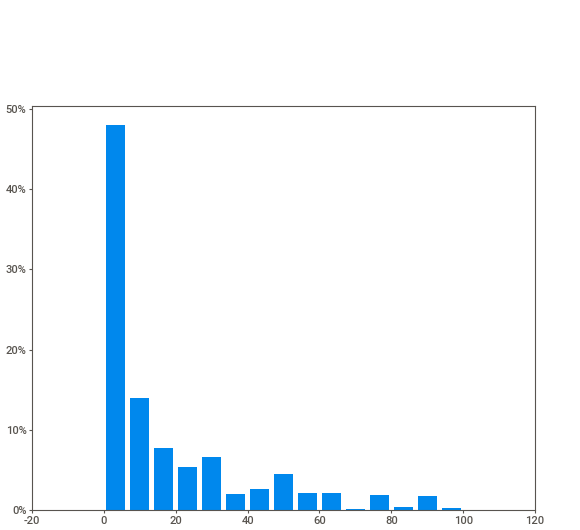
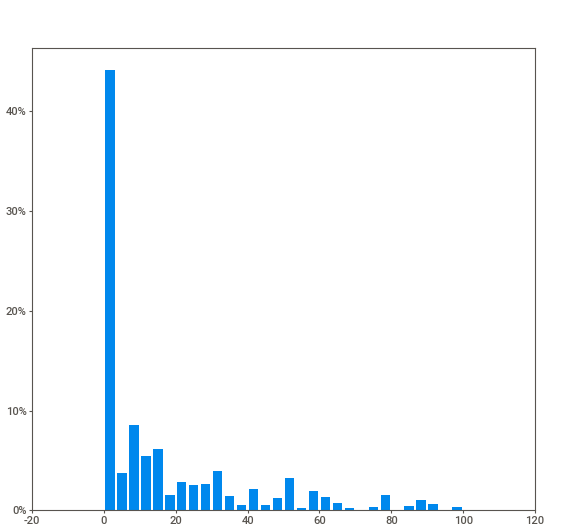
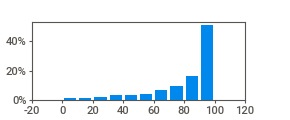
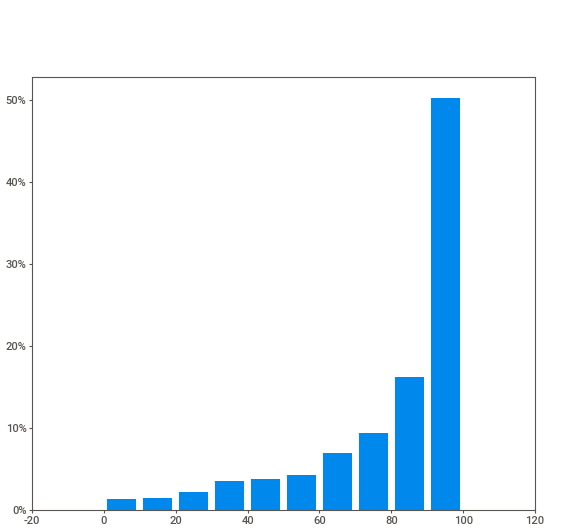
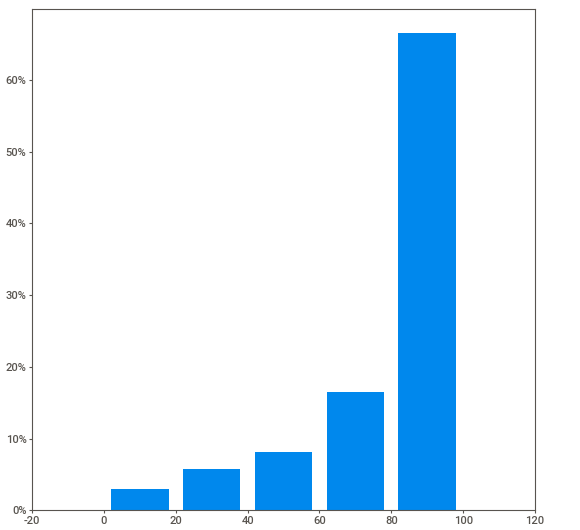
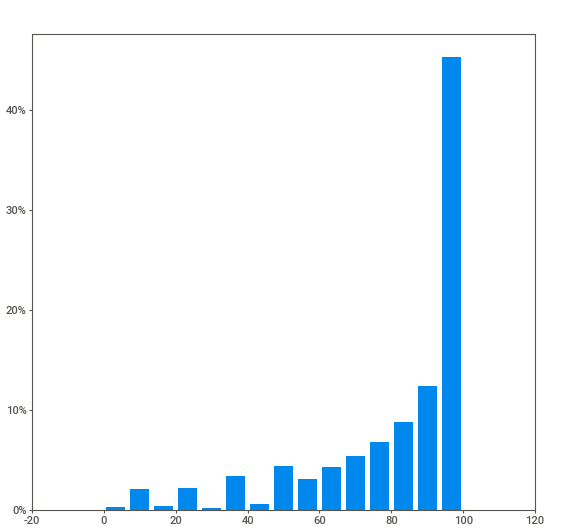
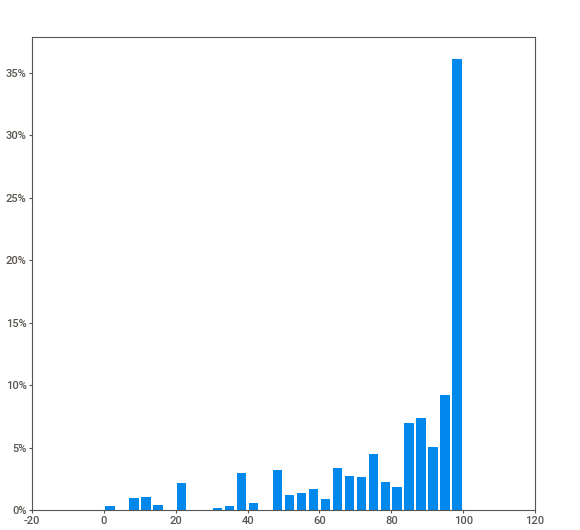
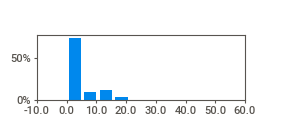
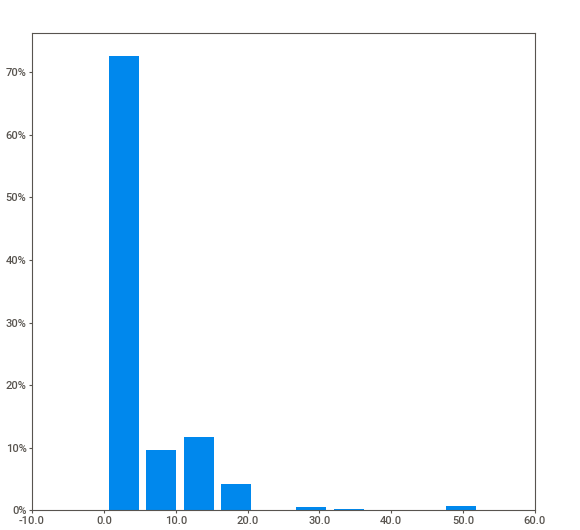
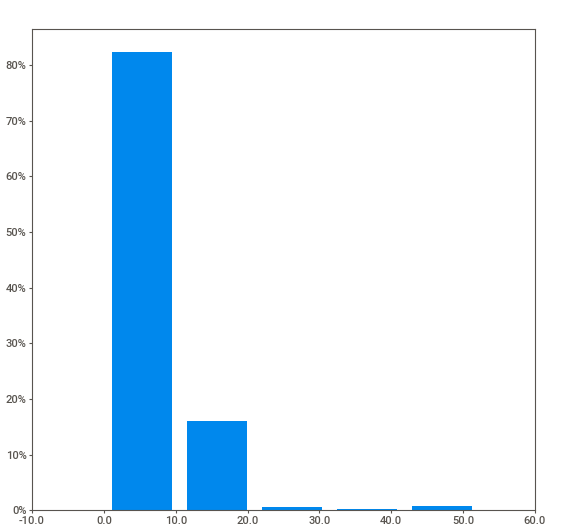
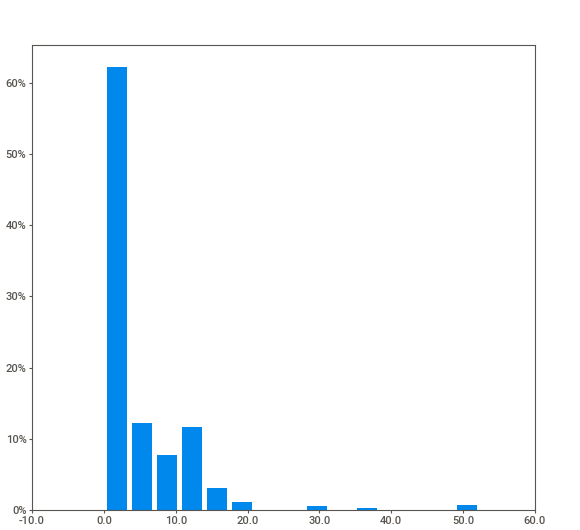
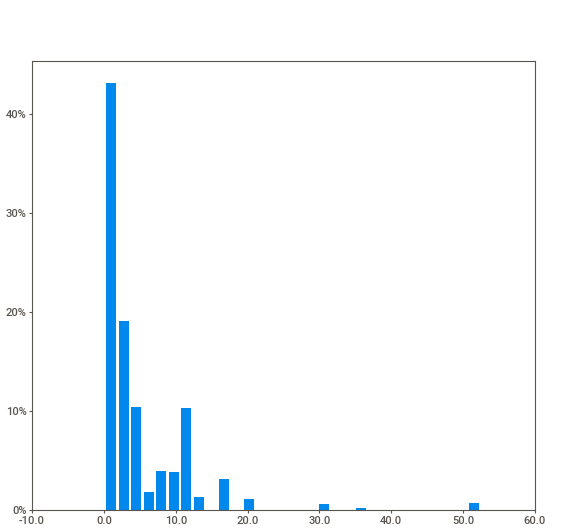
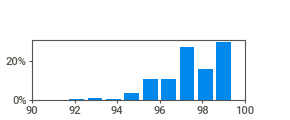
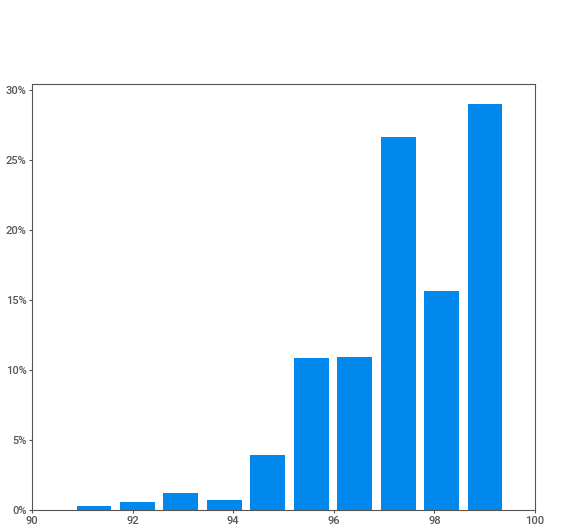
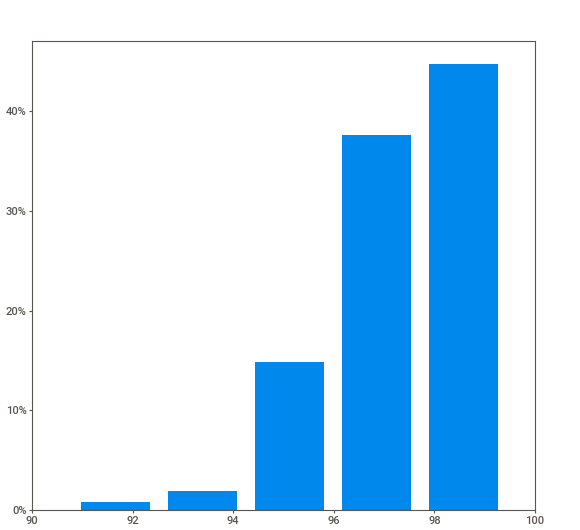
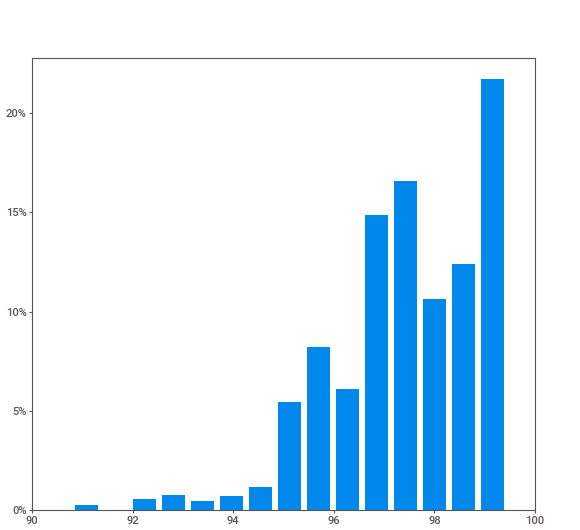
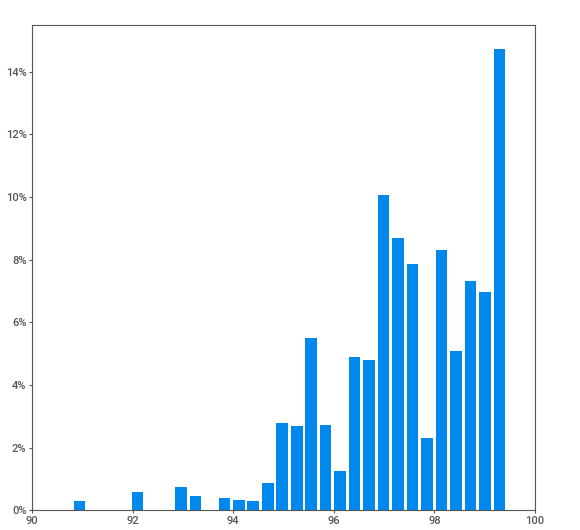
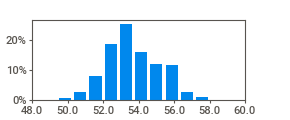
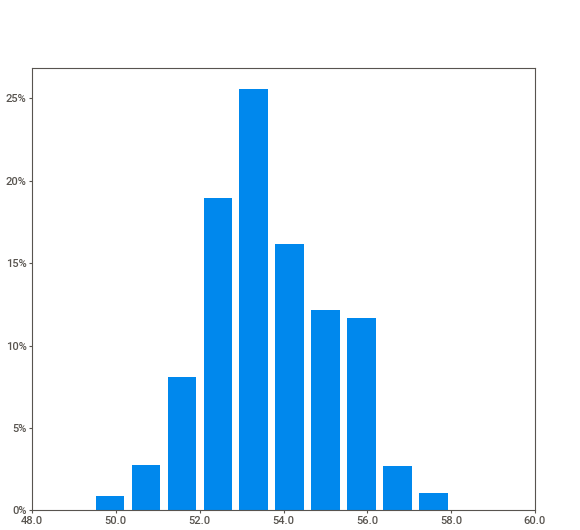
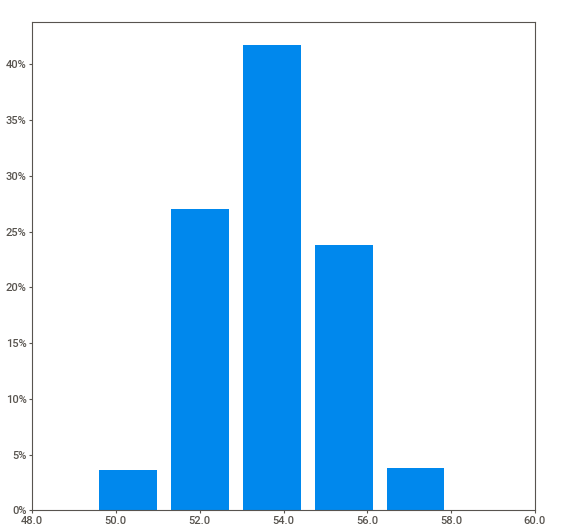
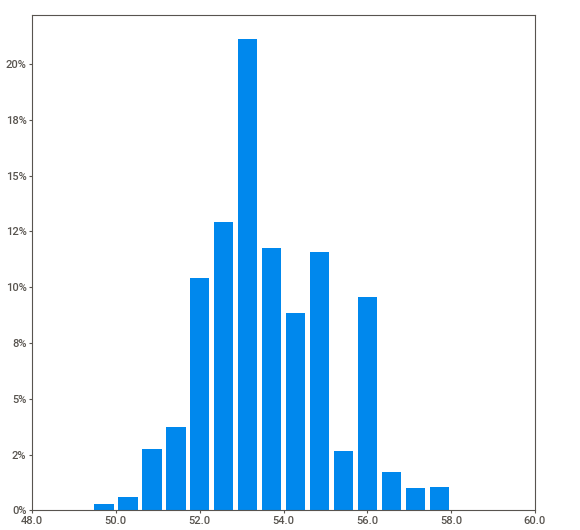
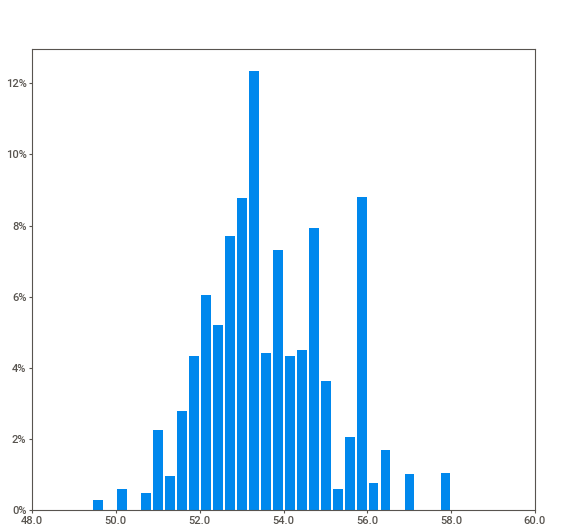
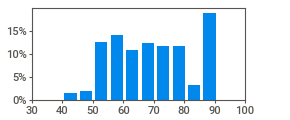
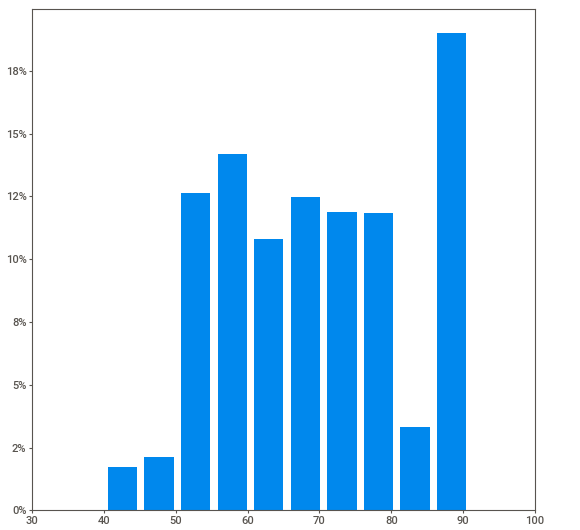
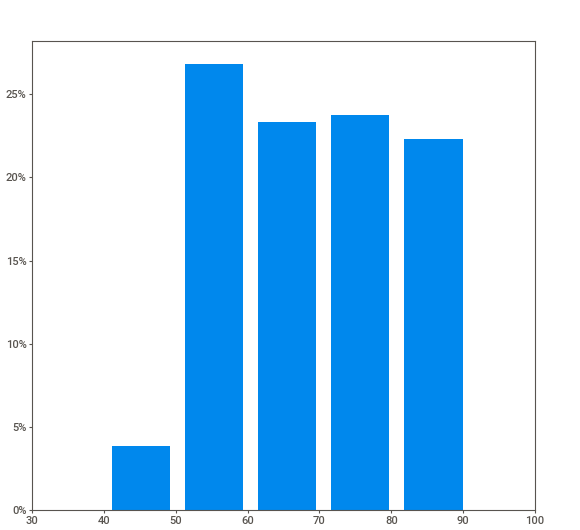
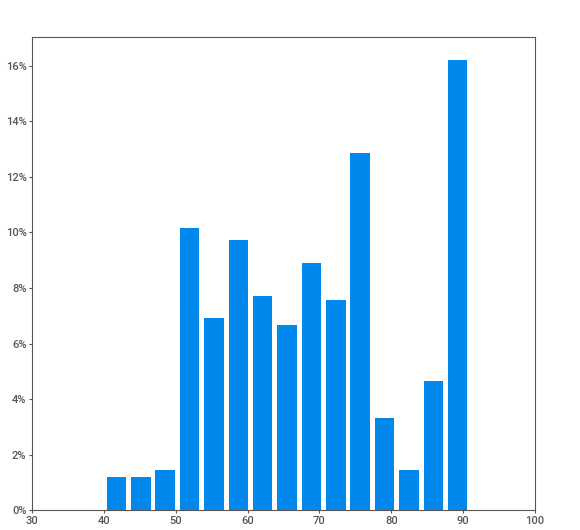
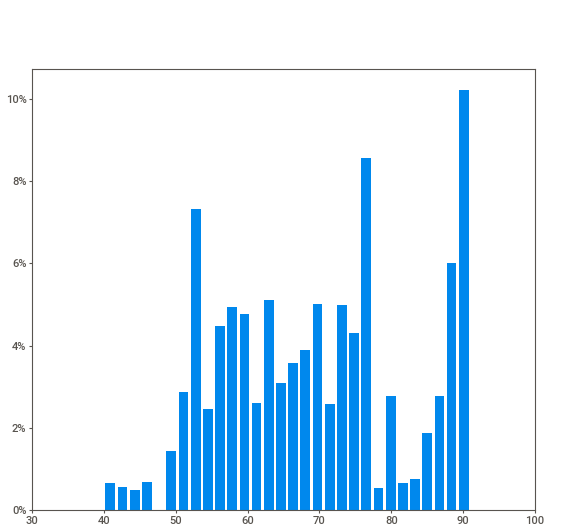
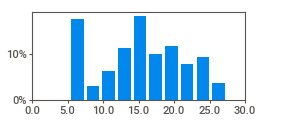
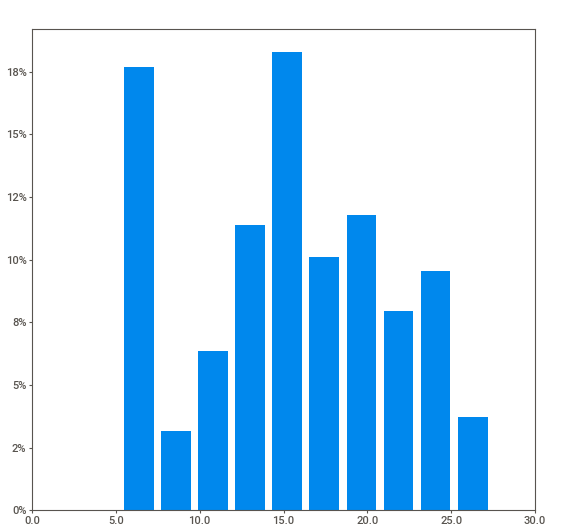
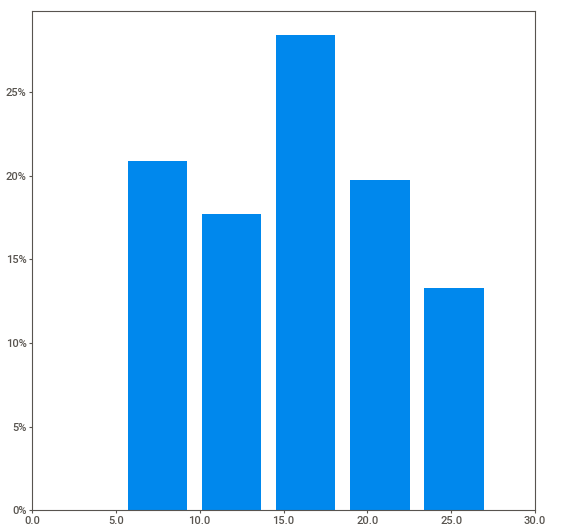
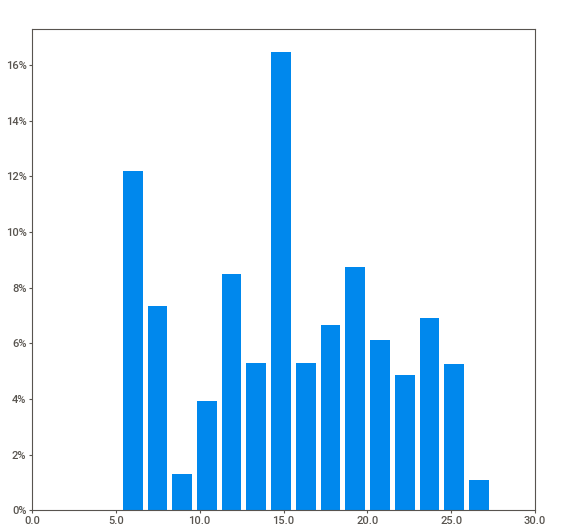
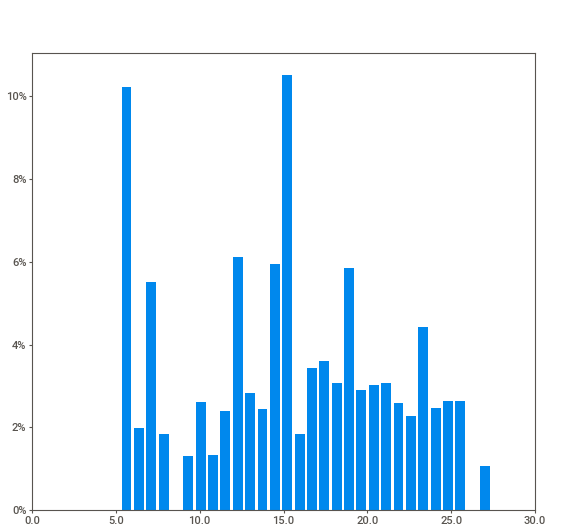
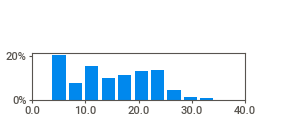
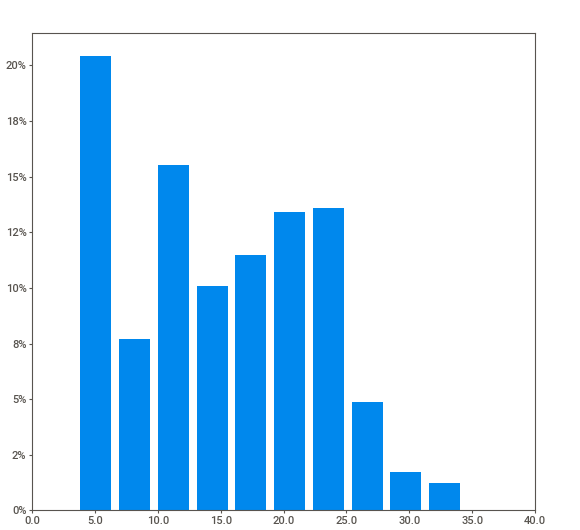
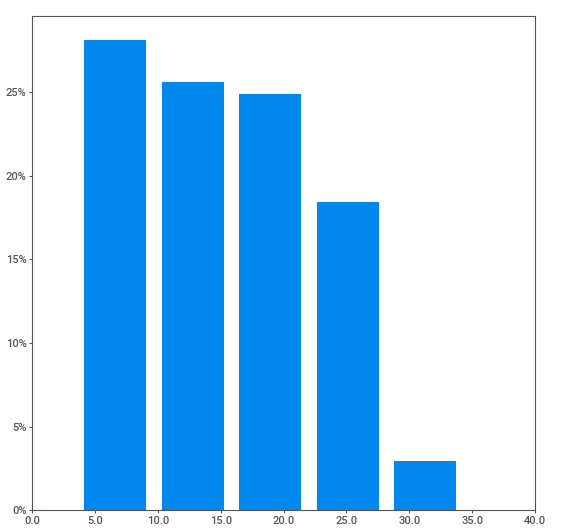
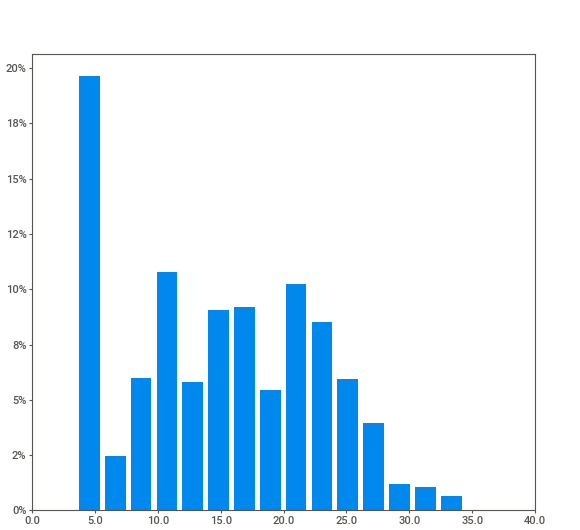
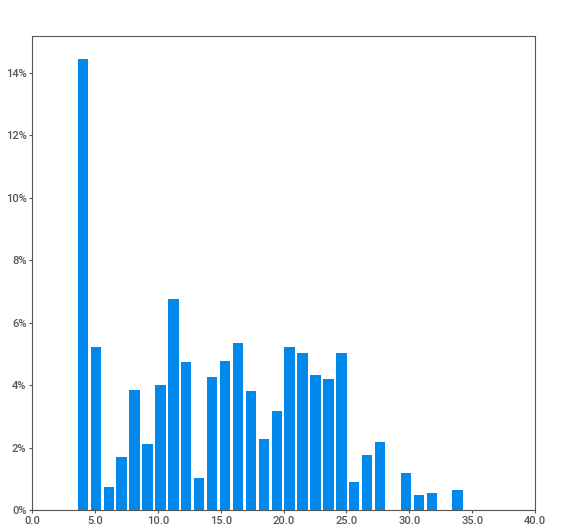
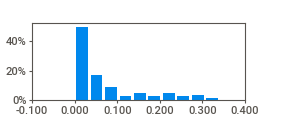
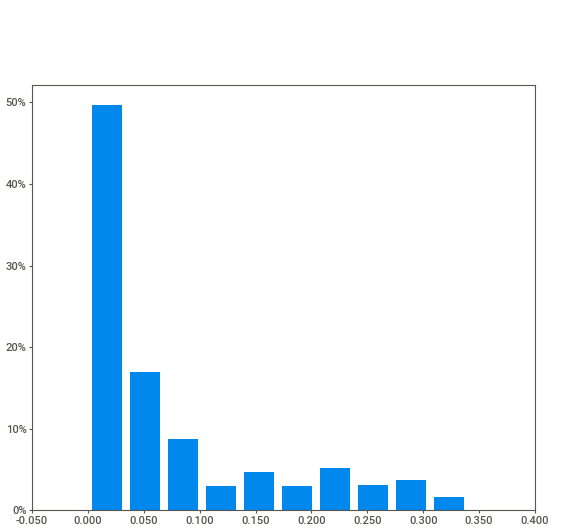
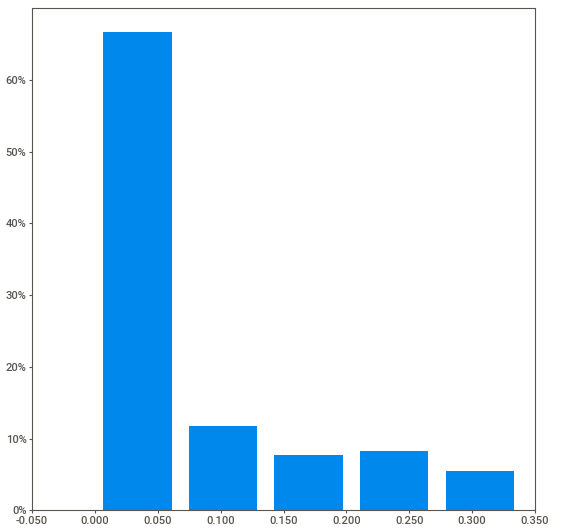
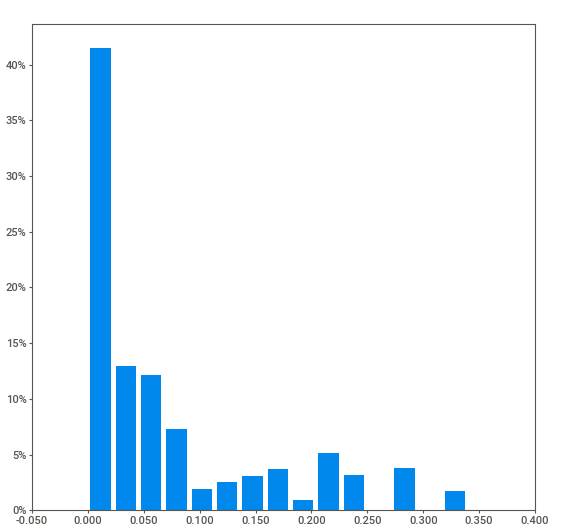
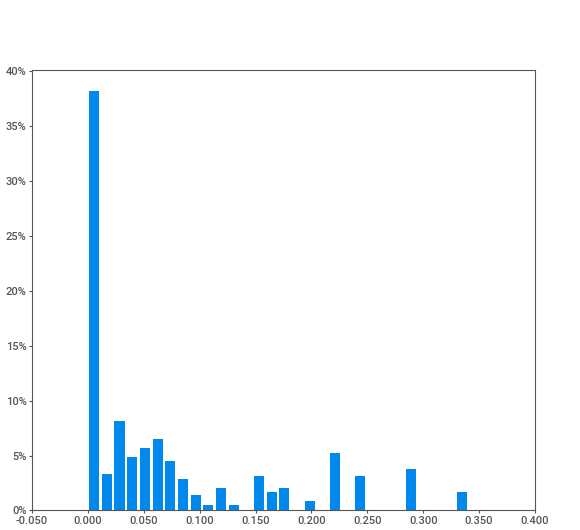
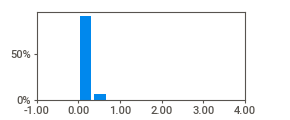
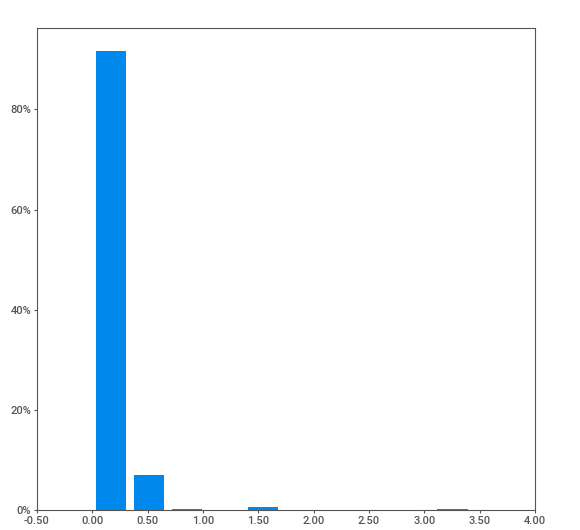
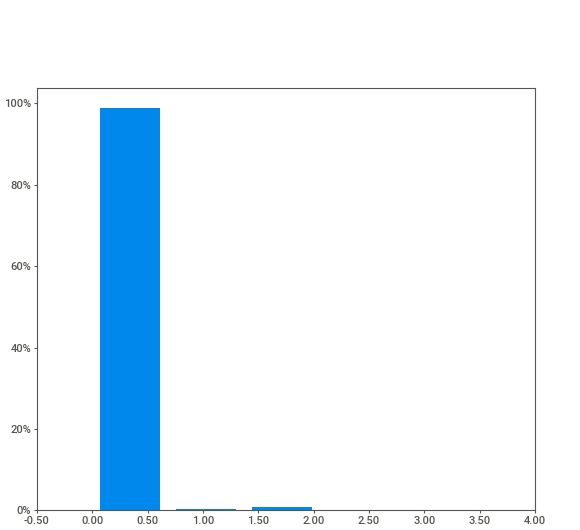
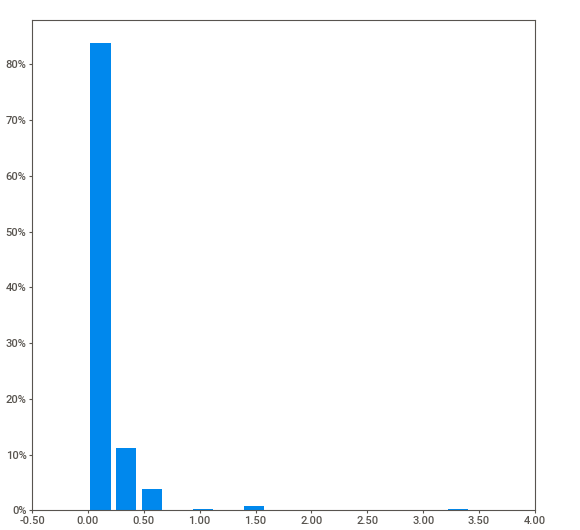
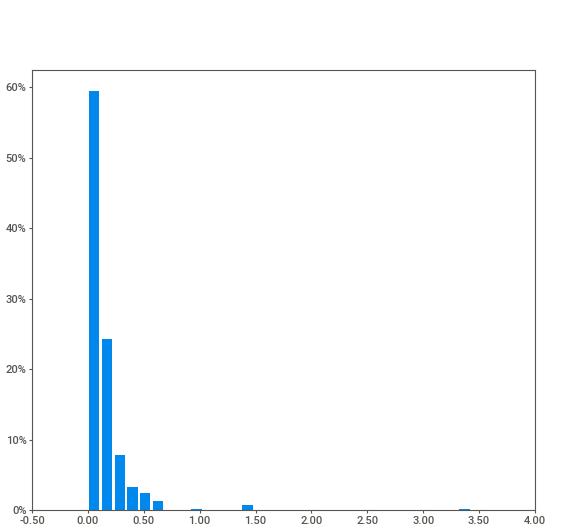
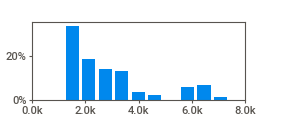
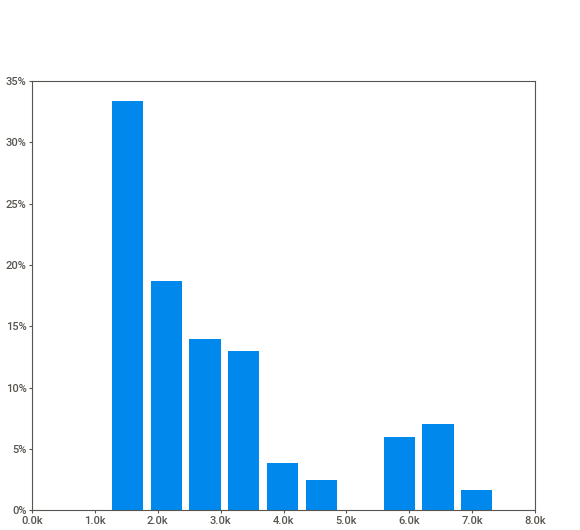
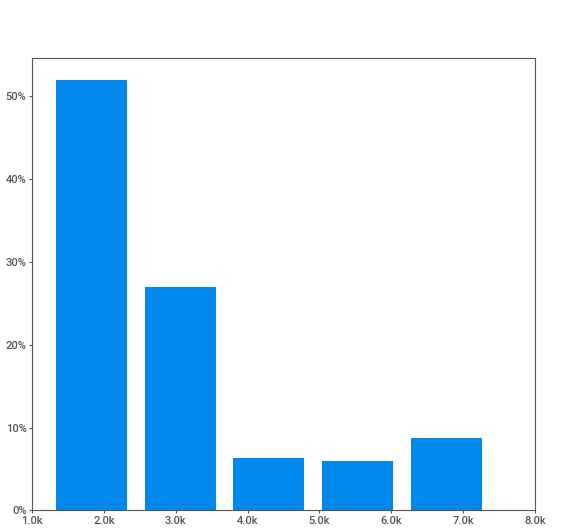
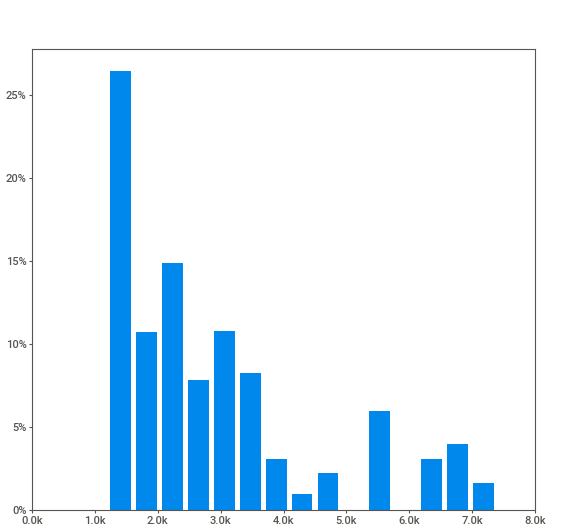
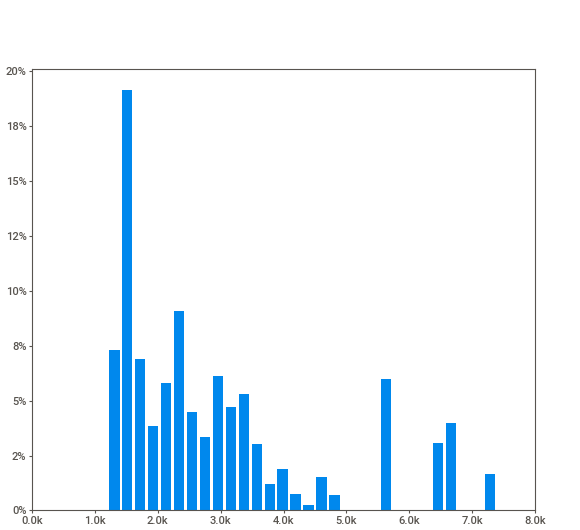
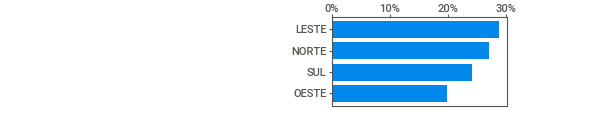
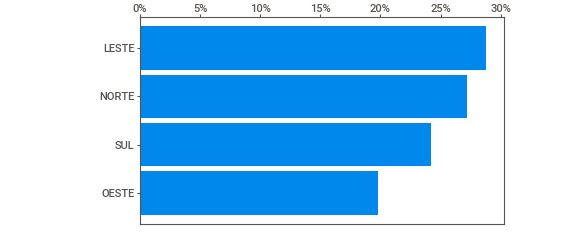
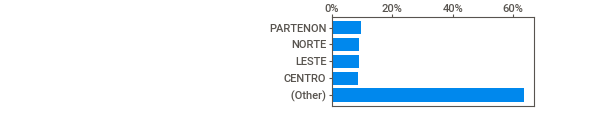
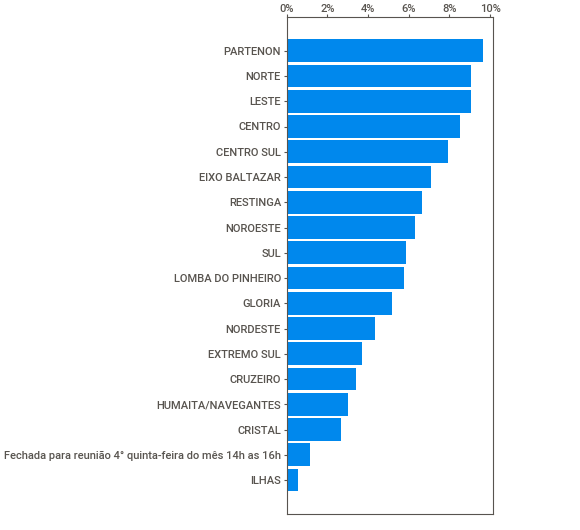
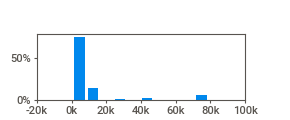
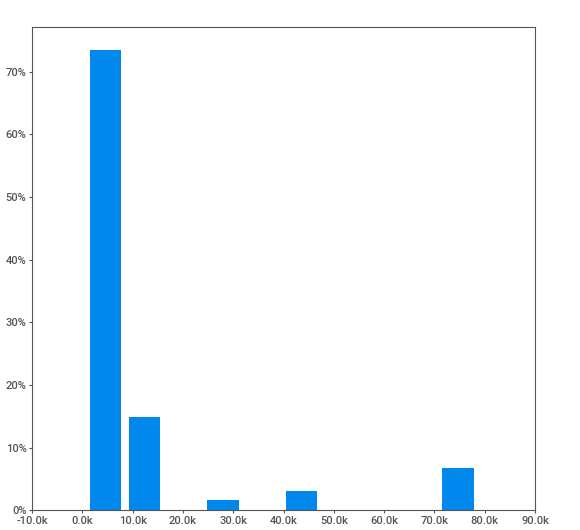
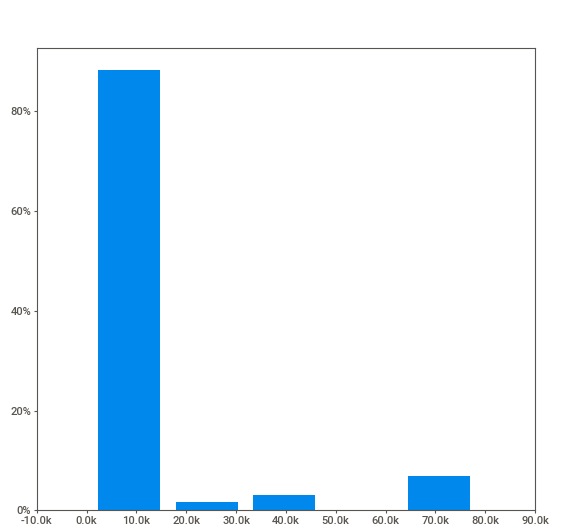
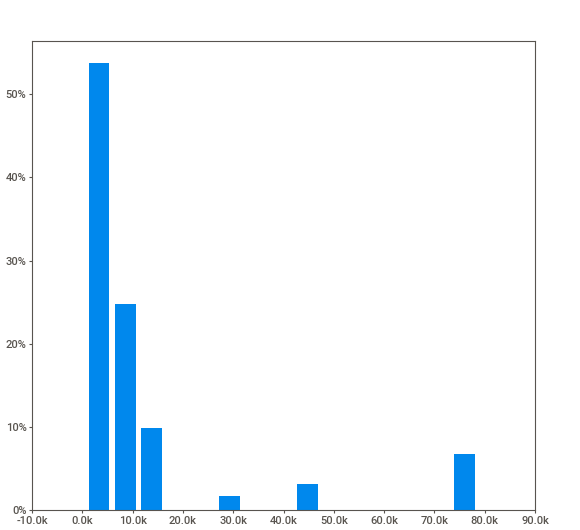
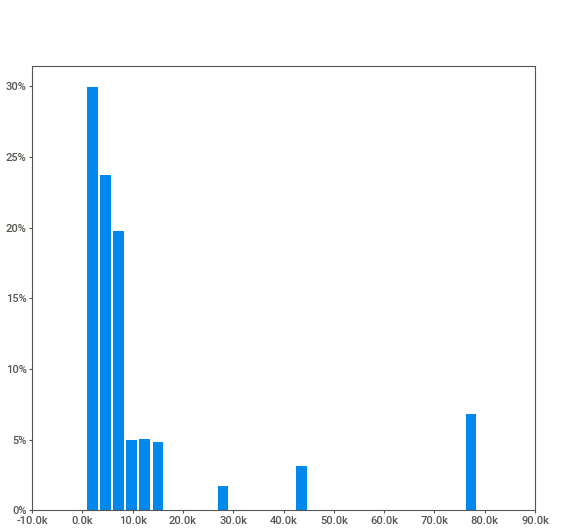
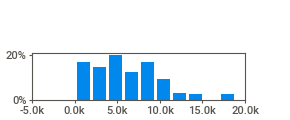
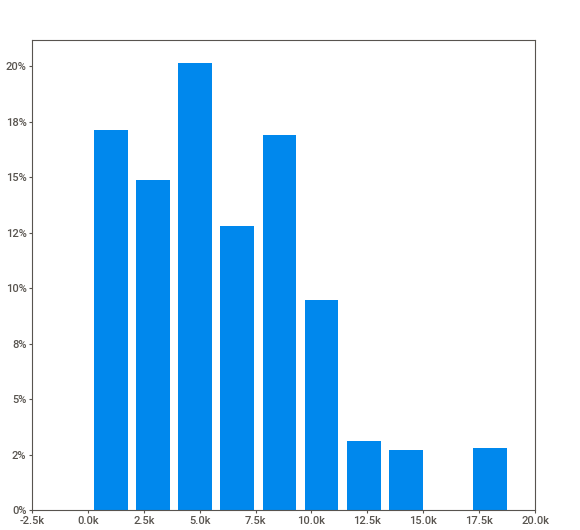
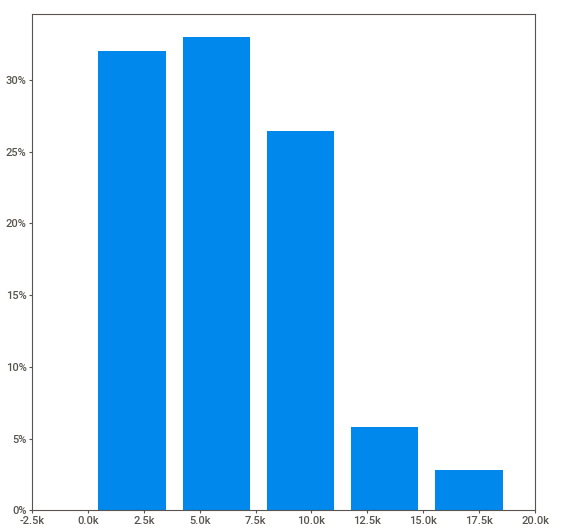
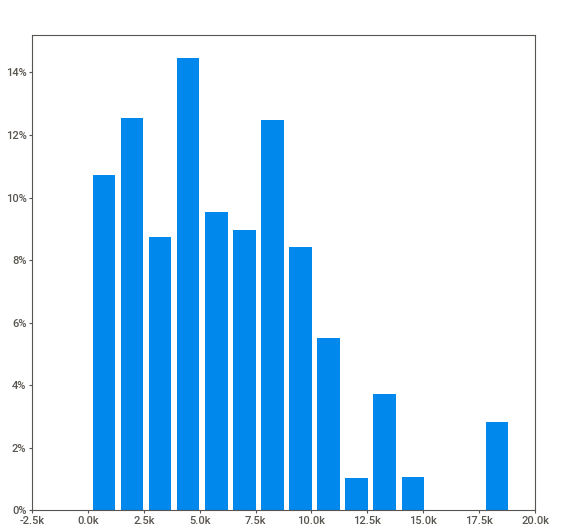
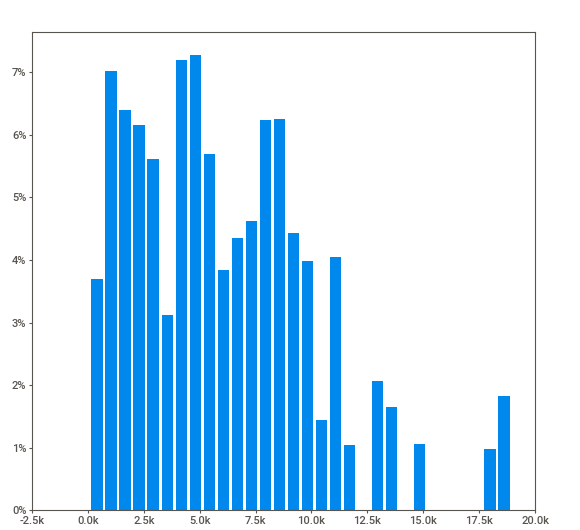
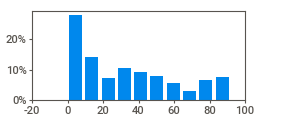
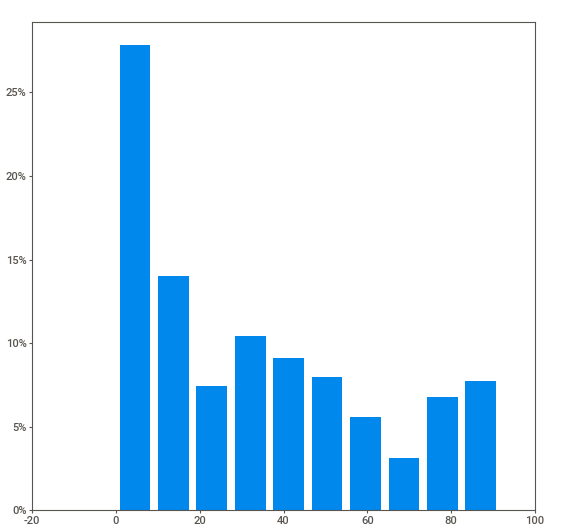
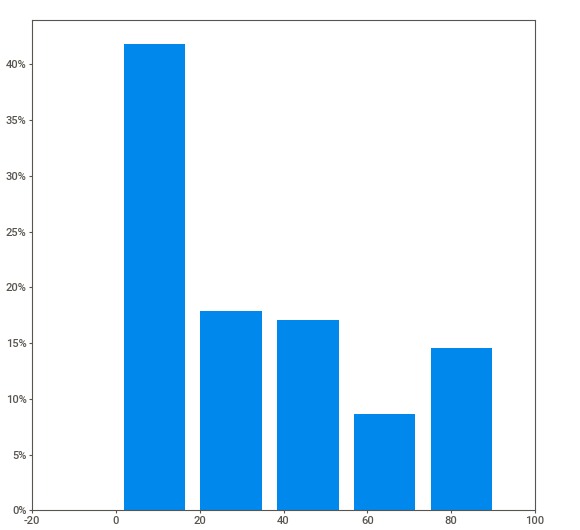
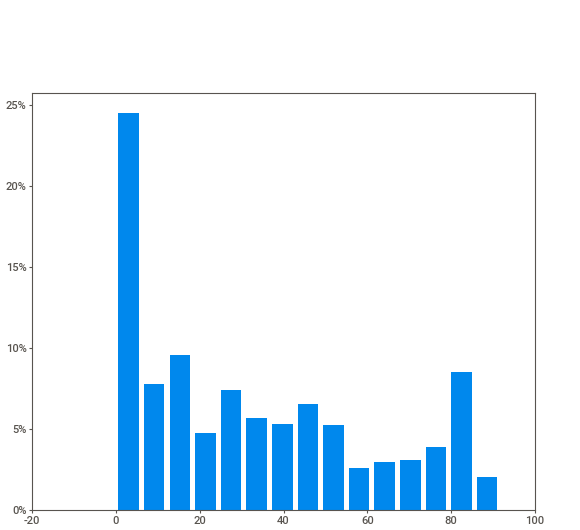
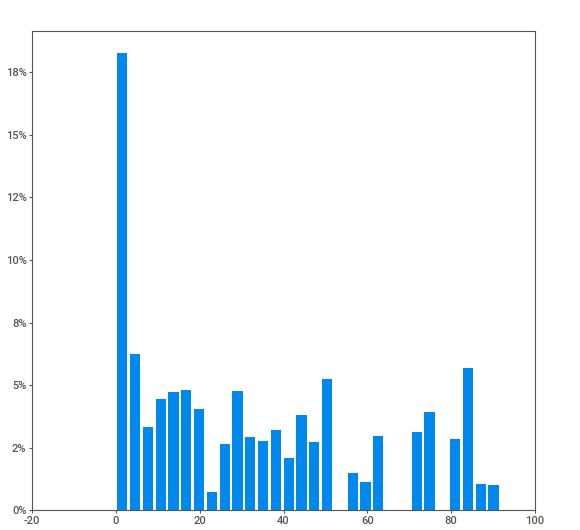
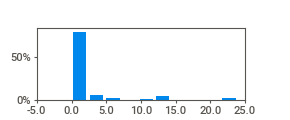
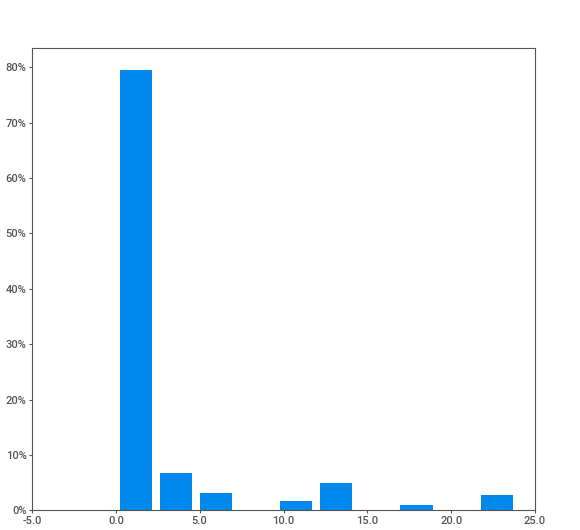
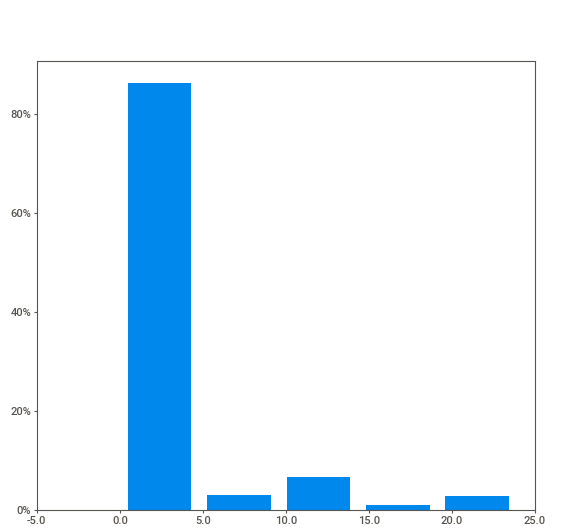
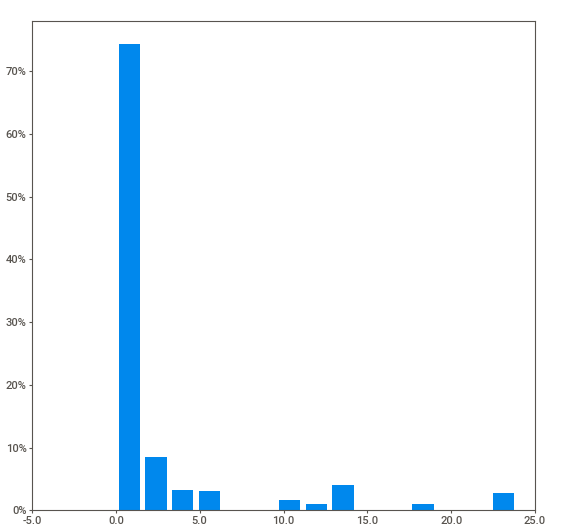
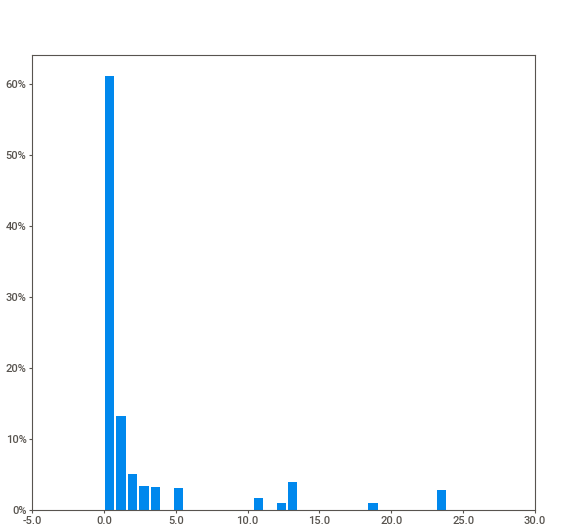
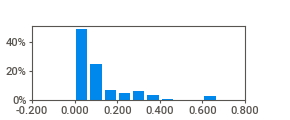
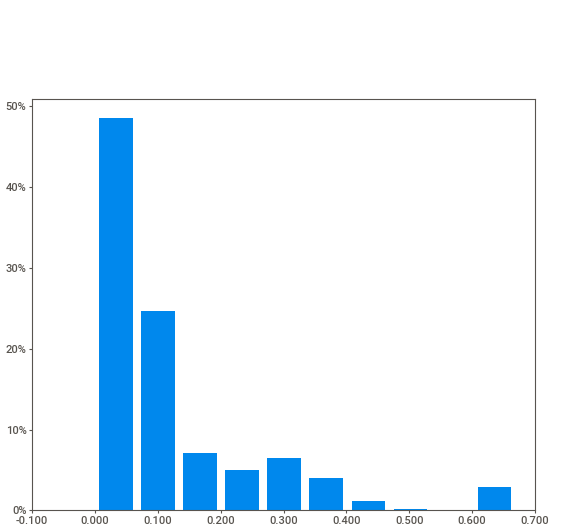
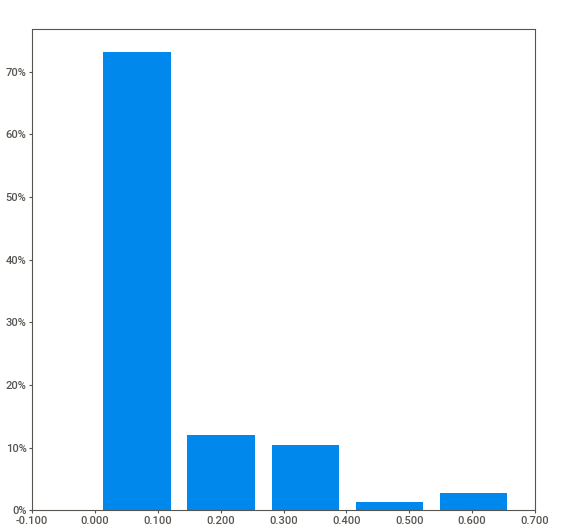
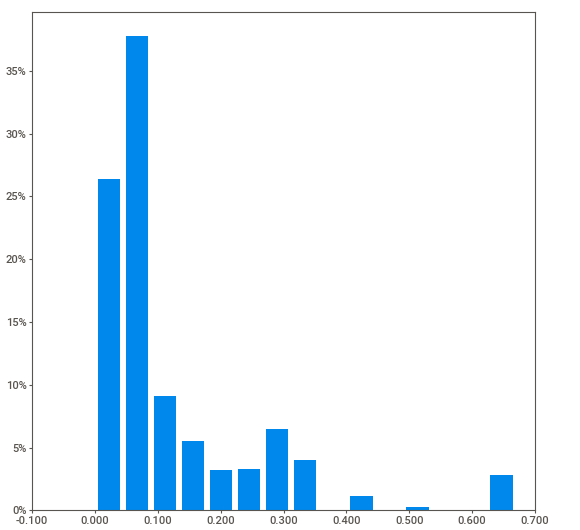
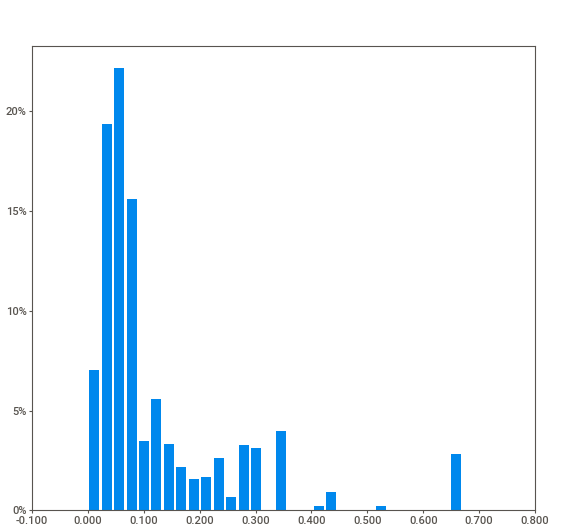
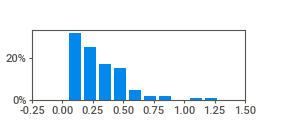
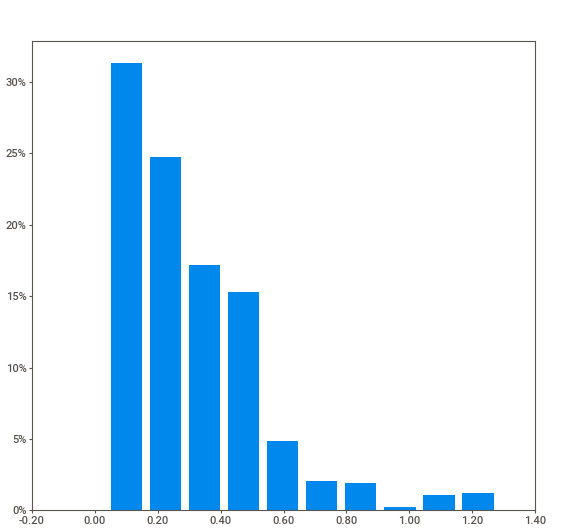
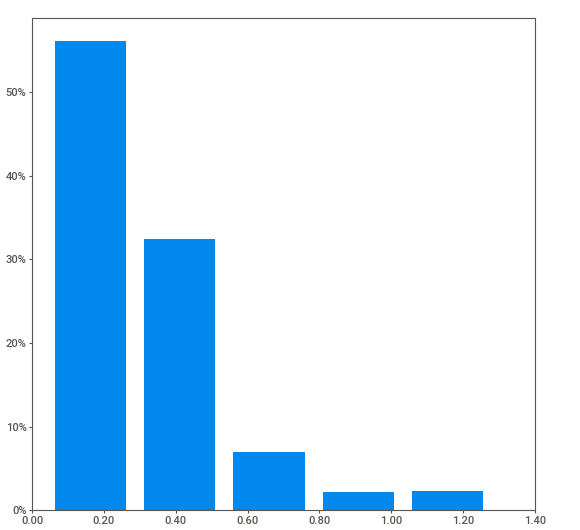
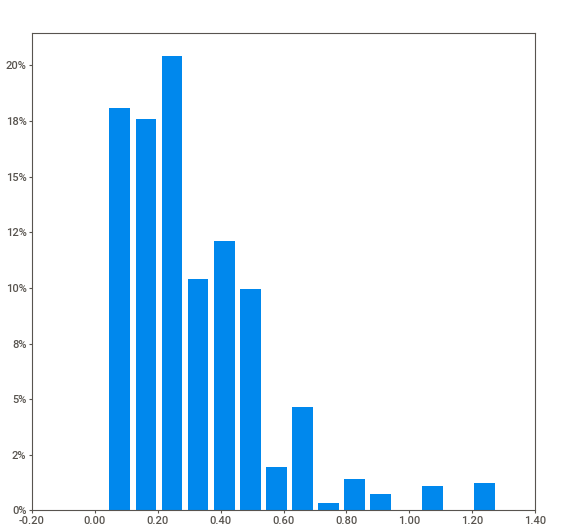
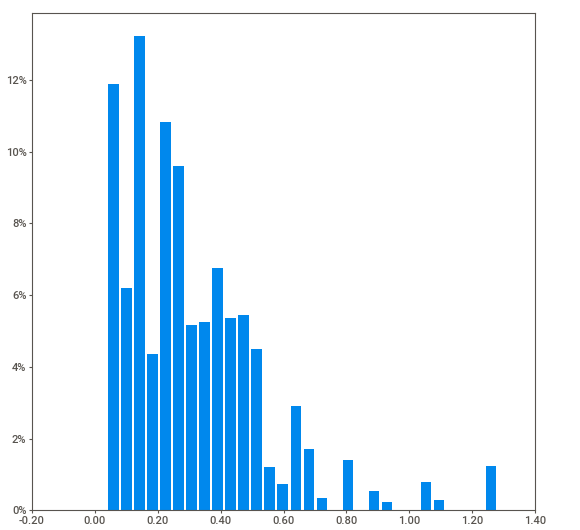
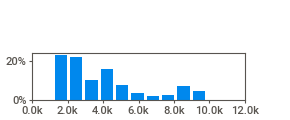
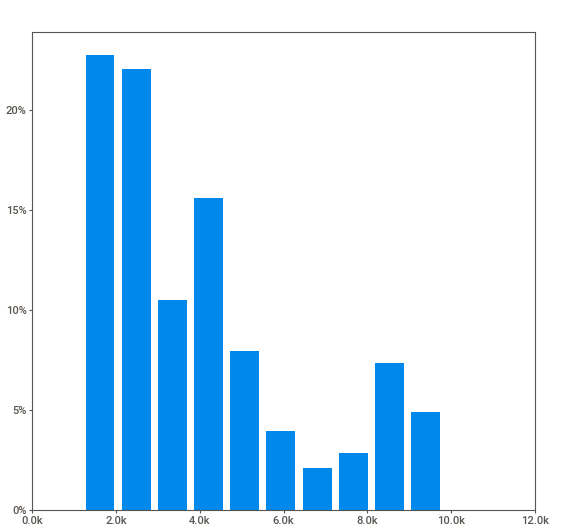
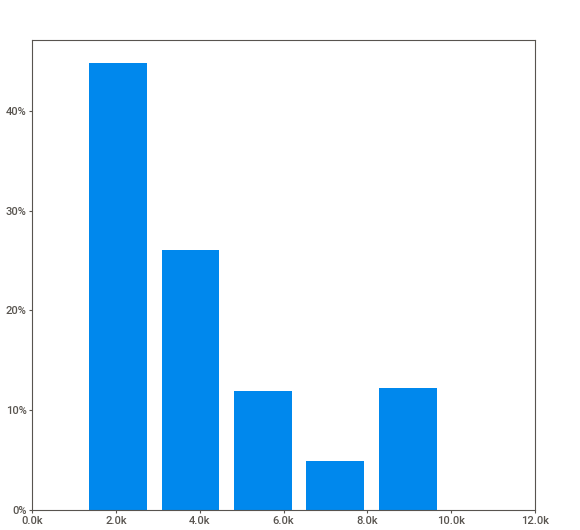
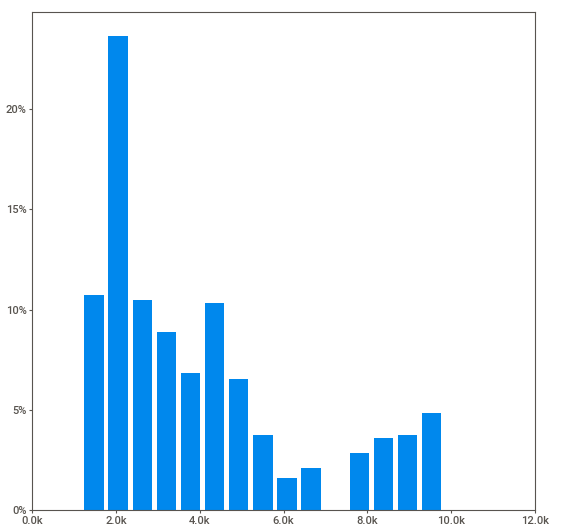
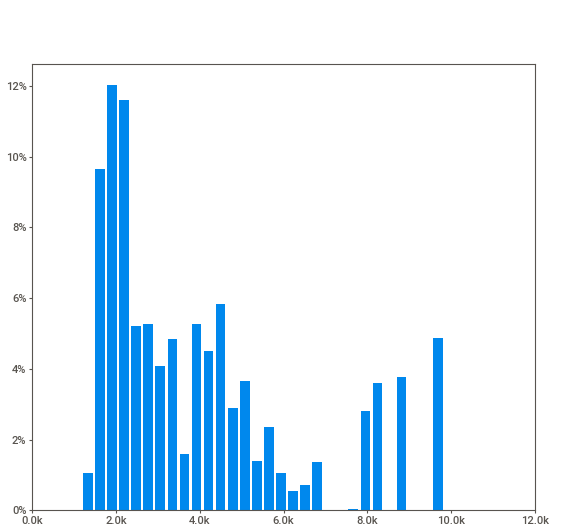
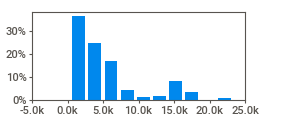
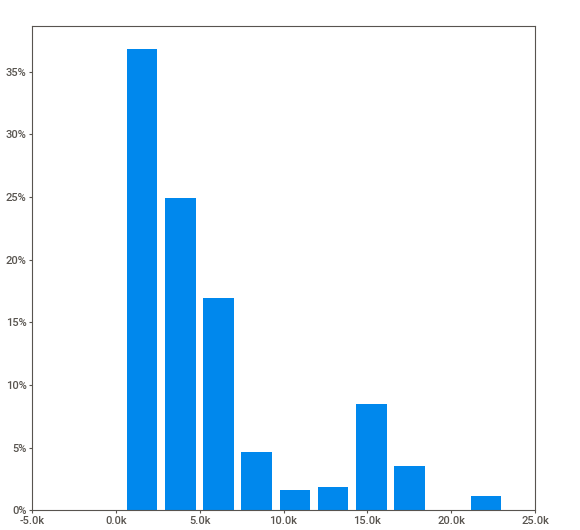
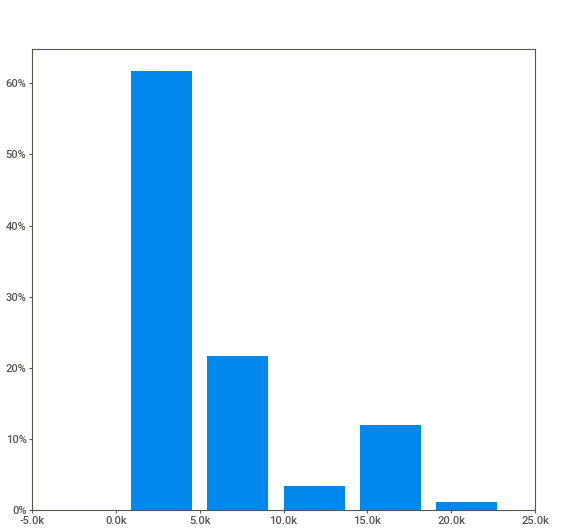
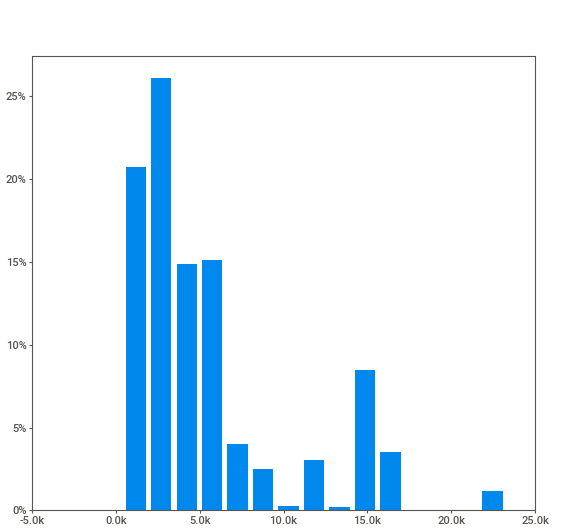
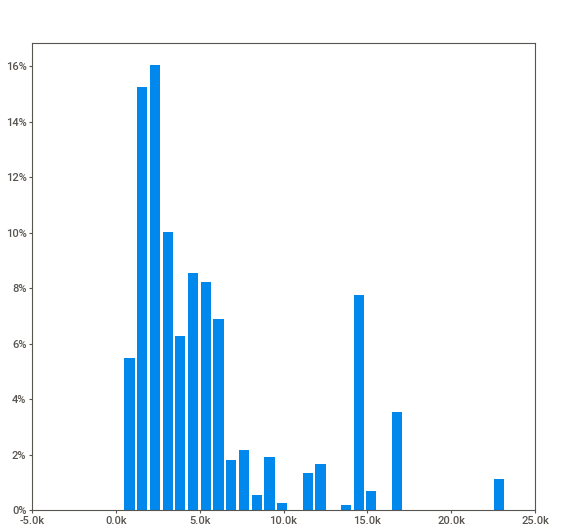
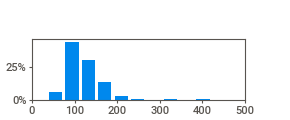
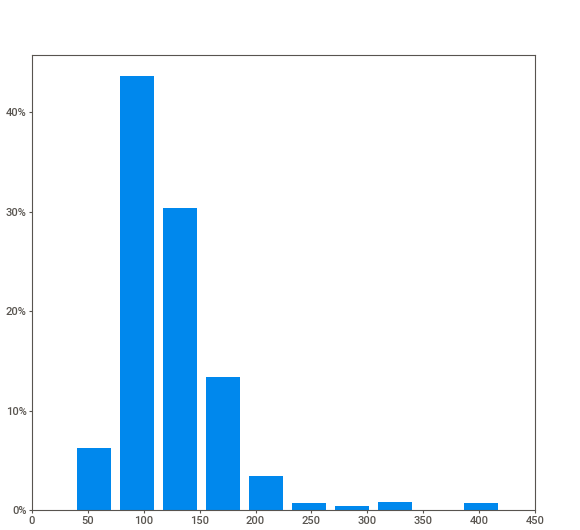
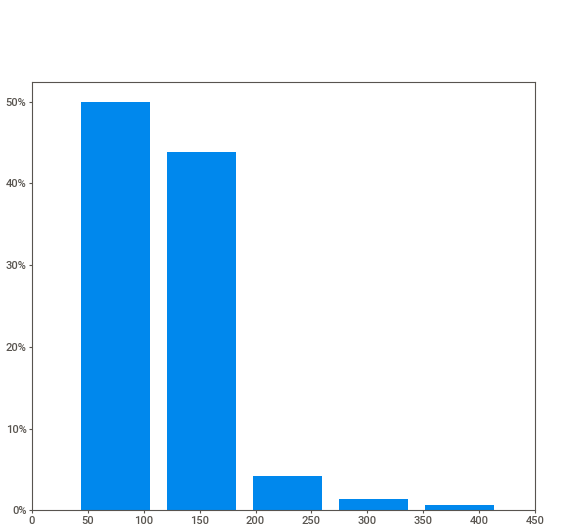
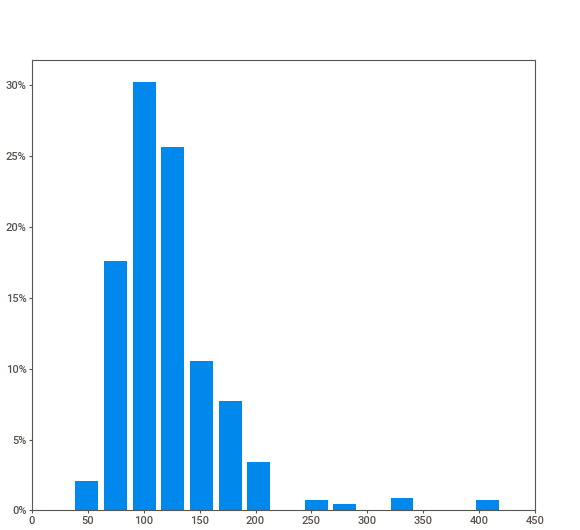
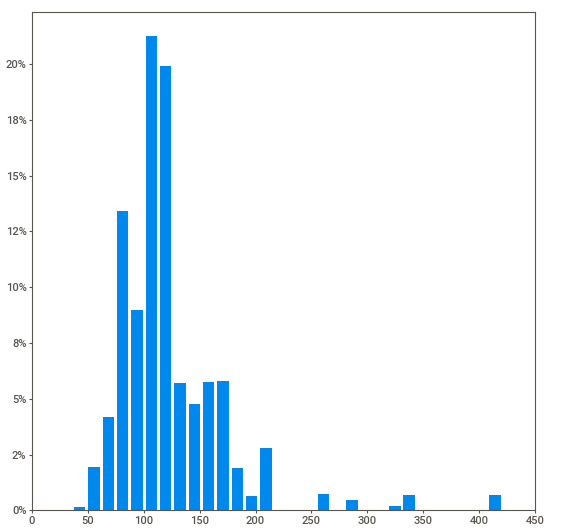
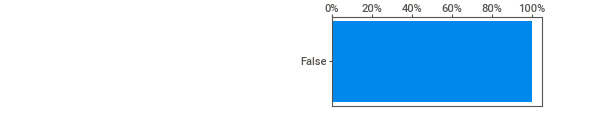
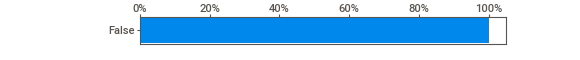

In [9]:
relatorio.show_notebook()

## 1.1 Remoção de colunas desnecessárias

Metadados de extração e colunas redundantes não entram na análise.

In [10]:
#df = df.drop(columns=DROP_COLS, errors='ignore')
#f.shape

DROP_COLS = [
    'data_extracao',
    'COD_IBGE_MUNICIPIO_EXECUTANTE_7D',
    'COD_IBGE_MUNICIPIO_EXECUTANTE_6D',
    'UF_EXECUTANTE',
    'ARQUIVO_ORIGEM',
]

df = df.drop(columns=DROP_COLS, errors='ignore')

## 2. Visão geral

In [11]:
df.head(5)

,ANO_SOLICITACAO,IDSOLICITACAO,SITUACAOSOLICITACAO,DATA_SOLICITACAO,CORREGULADOR,DIASFILAESPERA,COMPLEXIDADE,ESPECIALIDADE,ESPECIALIDADEMAE,CID,...,densidade_hab_km2,pct_apartamentos,razao_apart_casa,pct_est_saude,pct_est_religiosos,renda_media_winsor,renda_dp,renda_cv,flag_renda_suspeita,CID_ajustada
0,2018,747495,REALIZADA,2018-02-20,AMARELO,17,MEDIA,CIRURGIA BUCOMAXILOFACIAL CEO,CIRURGIA BUCOMAXILOFACIAL,K011,...,6888.552648,15.384615,0.226488,0.086919,0.434594,2760.800651,2878.711953,104.270910,False,K01
1,2018,756290,REALIZADA,2018-02-28,AZUL,14,MEDIA,CIRURGIA BUCOMAXILOFACIAL CEO,CIRURGIA BUCOMAXILOFACIAL,K021,...,2551.101002,4.696970,0.055722,0.050505,0.606061,1659.903950,1079.210649,65.016452,False,K02
2,2018,806777,REALIZADA,2018-04-12,AZUL,1,MEDIA,CIRURGIA BUCOMAXILOFACIAL CEO,CIRURGIA BUCOMAXILOFACIAL,K011,...,1211.603418,38.096785,0.826056,0.064956,0.162390,3993.913191,4774.691182,119.549198,False,K01
3,2018,730573,REALIZADA,2018-02-01,LARANJA,5,MEDIA,PERIODONTIA,ODONTO PERIODONTIA,K061,...,958.843801,0.537934,0.006186,0.037099,0.686329,1700.161961,1716.836238,100.980746,False,K06
4,2018,744023,ENCERRADA,2018-02-16,NENHUM,0,MEDIA,PERIODONTIA,ODONTO PERIODONTIA,K051,...,1028.225601,9.515997,0.117814,0.032814,0.246103,3517.723782,4208.299792,119.631331,False,K05


In [12]:
df.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1912556 entries, 0 to 1912555
Data columns (total 52 columns):
 #   Column                  Dtype         
---  ------                  -----         
 0   ANO_SOLICITACAO         int64         
 1   IDSOLICITACAO           category      
 2   SITUACAOSOLICITACAO     category      
 3   DATA_SOLICITACAO        datetime64[us]
 4   CORREGULADOR            category      
 5   DIASFILAESPERA          int64         
 6   COMPLEXIDADE            category      
 7   ESPECIALIDADE           category      
 8   ESPECIALIDADEMAE        category      
 9   CID                     category      
 10  IDPACIENTE              category      
 11  MUNICIPIO_RESIDENCIA    category      
 12  IDADE                   int64         
 13  CNES_SOLICITANTE        category      
 14  UNIDADESOLICITANTE      category      
 15  SITUACAOAGENDA          category      
 16  DATAHORA_CONSULTA       datetime64[us]
 17  CNESEXECUTANTE          category      
 18  UN

In [13]:
print(f"Linhas: {df.shape[0]:,} | Colunas: {df.shape[1]}")
print(f"Memória: {df.memory_usage(deep=True).sum() / 1024**2:,.1f} MB")

Linhas: 1,912,556 | Colunas: 52
Memória: 1,179.1 MB


## 3. Valores ausentes

In [14]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'n_ausentes': missing, 'pct_ausentes': missing_pct})
missing_df = missing_df[missing_df['n_ausentes'] > 0]
missing_df

,n_ausentes,pct_ausentes
STATUSREGIONALIZACAO,1912413,99.99
MUNICIPIO_EXECUTANTE,532778,27.86
CNESEXECUTANTE,532778,27.86
UNIDADEEXECUTANTE,532778,27.86
SITUACAOAGENDA,532778,27.86
DATAHORA_CONSULTA,532778,27.86
renda_mediana_aprox,21201,1.11
pct_Indígena,21201,1.11
distrito_sanitario,21201,1.11
n_enderecos_total,21201,1.11


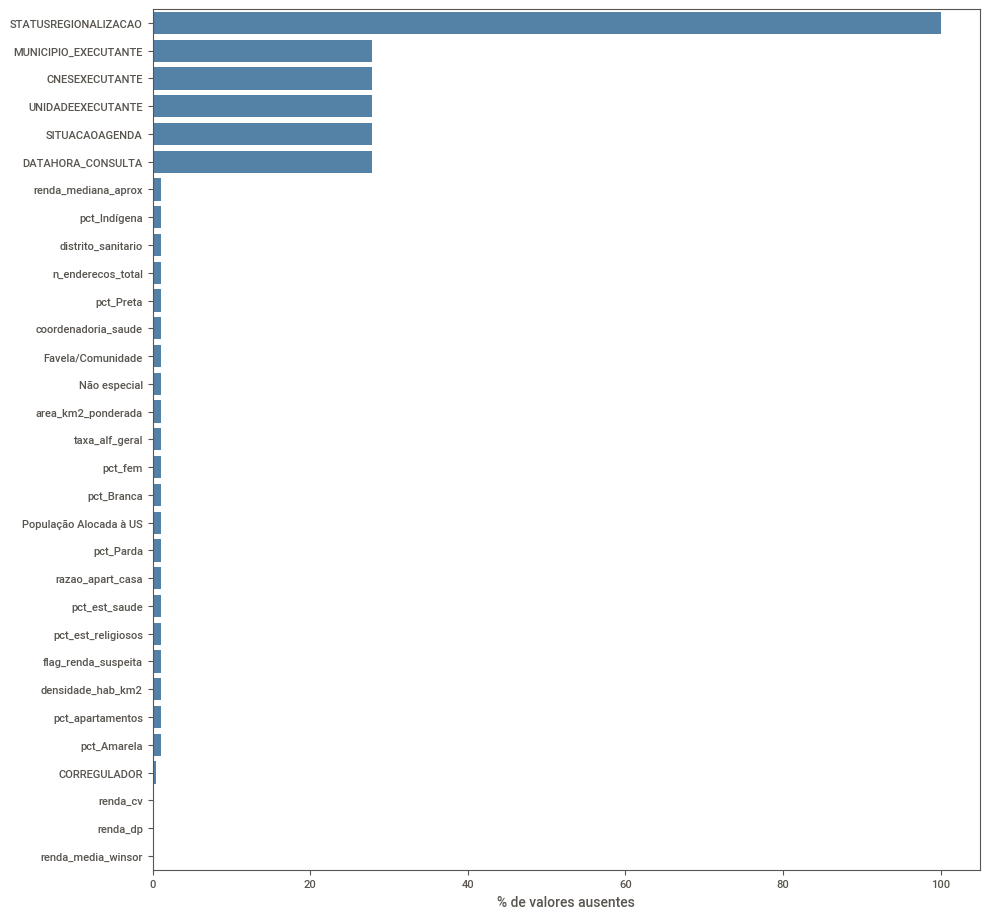

In [15]:
if not missing_df.empty:
    fig, ax = plt.subplots(figsize=(10, max(3, len(missing_df) * 0.3)))
    sns.barplot(x=missing_df['pct_ausentes'], y=missing_df.index, ax=ax, color='steelblue')
    ax.set_xlabel('% de valores ausentes')
    ax.set_ylabel('')
    plt.tight_layout()
    plt.show()
else:
    print('Sem valores ausentes.')

## 4. Duplicatas

In [16]:
n_dup = df.duplicated().sum()
print(f"Linhas duplicadas: {n_dup:,} ({n_dup / len(df) * 100:.2f}%)")

Linhas duplicadas: 0 (0.00%)


## 5. Identificação automática de tipos de coluna

Tenta converter colunas de texto que parecem datas, e separa numéricas vs. categóricas para as análises seguintes.

In [17]:
ID_COLS = []

DATE_FORMAT = '%Y-%m-%d %H:%M:%S.%f'

date_cols = [c for c in df.columns if pd.api.types.is_datetime64_any_dtype(df[c])]

for col in df.select_dtypes(include='object').columns:
    if col in ID_COLS or col in date_cols:
        continue
    sample = df[col].dropna().head(200)
    if sample.empty:
        continue
    parsed = pd.to_datetime(sample, format=DATE_FORMAT, errors='coerce')
    if parsed.notna().mean() > 0.9:
        date_cols.append(col)

for col in date_cols:
    if not pd.api.types.is_datetime64_any_dtype(df[col]):
        df[col] = pd.to_datetime(df[col], format=DATE_FORMAT, errors='coerce')

numeric_cols = [c for c in df.select_dtypes(include=np.number).columns if c not in ID_COLS]
categorical_cols = [c for c in df.select_dtypes(include='object').columns if c not in date_cols]

print('Colunas de data detectadas:', date_cols)
print('Colunas numéricas:', numeric_cols)
print('Colunas categóricas (inclui IDs/códigos):', categorical_cols)

Colunas de data detectadas: ['DATA_SOLICITACAO', 'DATAHORA_CONSULTA']
Colunas numéricas: ['ANO_SOLICITACAO', 'DIASFILAESPERA', 'IDADE', 'População Alocada à US', 'Favela/Comunidade', 'Não especial', 'area_km2_ponderada', 'taxa_alf_geral', 'pct_fem', 'pct_Branca', 'pct_Parda', 'pct_Preta', 'pct_Amarela', 'pct_Indígena', 'renda_mediana_aprox', 'n_enderecos_total', 'densidade_hab_km2', 'pct_apartamentos', 'razao_apart_casa', 'pct_est_saude', 'pct_est_religiosos', 'renda_media_winsor', 'renda_dp', 'renda_cv']
Colunas categóricas (inclui IDs/códigos): ['censo_unidade_saude', 'coordenadoria_saude', 'distrito_sanitario', 'flag_renda_suspeita', 'CID_ajustada']


## 6. Estatísticas descritivas — variáveis numéricas

In [18]:
df[numeric_cols].describe().T if numeric_cols else print('Nenhuma coluna numérica identificada.')

,count,mean,std,min,25%,50%,75%,max
ANO_SOLICITACAO,1912556.0,2022.159599,2.308279,2018.000000,2020.000000,2022.000000,2024.000000,2026.000000
DIASFILAESPERA,1912556.0,262.641084,456.388223,0.000000,7.000000,56.000000,281.000000,2288.000000
IDADE,1912556.0,50.032297,22.779658,0.000000,33.000000,54.000000,68.000000,125.000000
População Alocada à US,1891355.0,19133.222248,25698.932423,1567.911416,5652.675334,10551.855335,17384.649404,108373.419555
Favela/Comunidade,1891355.0,16.905520,22.794599,0.000000,0.000000,7.044471,26.373622,100.000000
Não especial,1891355.0,81.337485,23.165481,0.000000,71.149390,90.616069,99.221392,100.000000
area_km2_ponderada,1891355.0,4.904621,6.646105,0.143006,0.970468,2.692301,7.228719,52.329667
taxa_alf_geral,1891355.0,97.435185,1.492958,90.799334,96.573589,97.517894,98.658848,99.438694
pct_fem,1891355.0,53.667502,1.493131,49.432341,52.694575,53.356559,54.759712,58.010542
pct_Branca,1891355.0,69.548676,13.097413,40.054764,58.313425,69.381109,79.122343,90.935593


## 7. Distribuição das variáveis numéricas

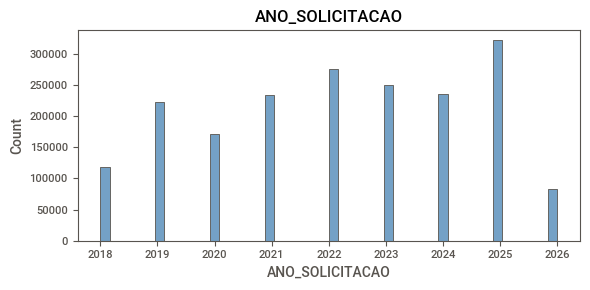

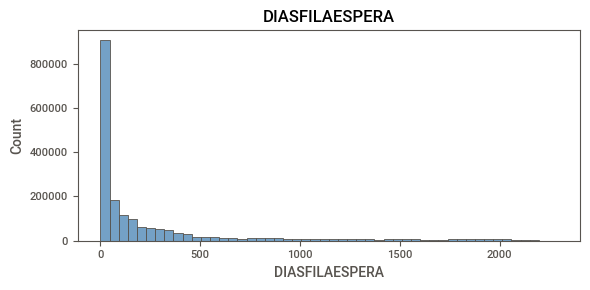

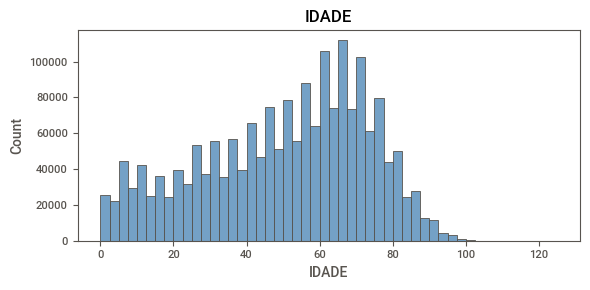

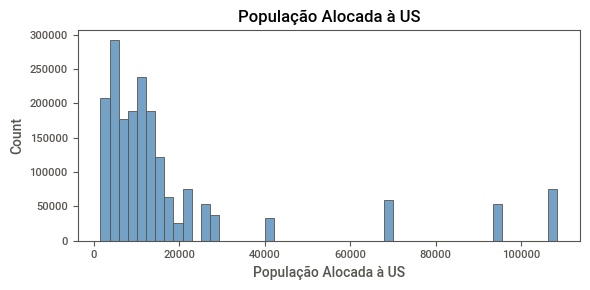

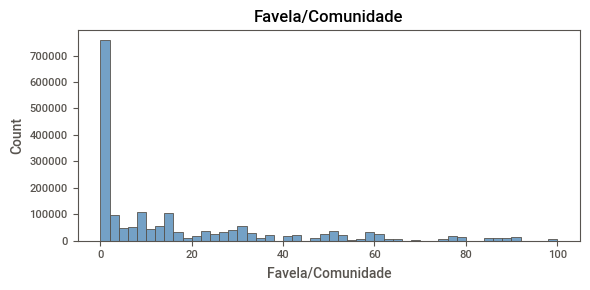

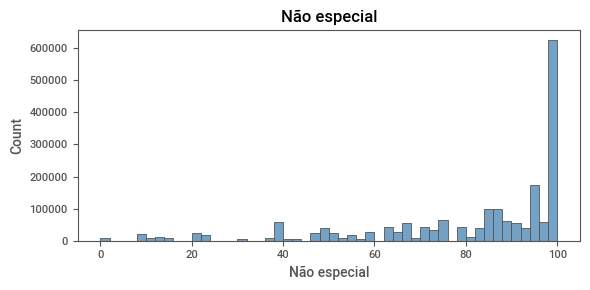

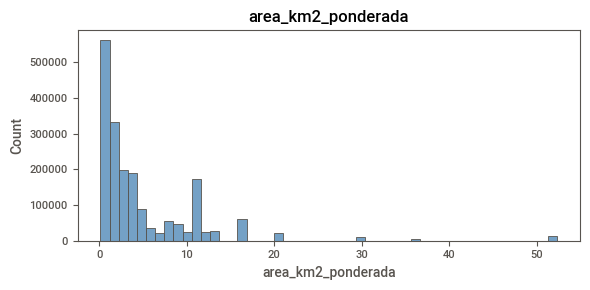

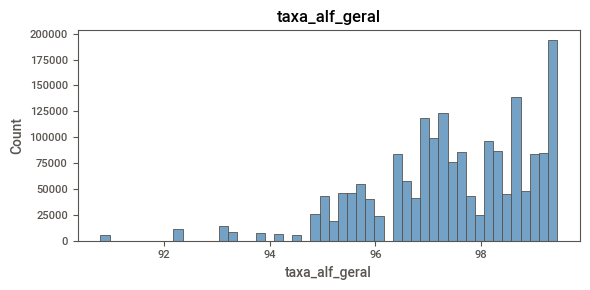

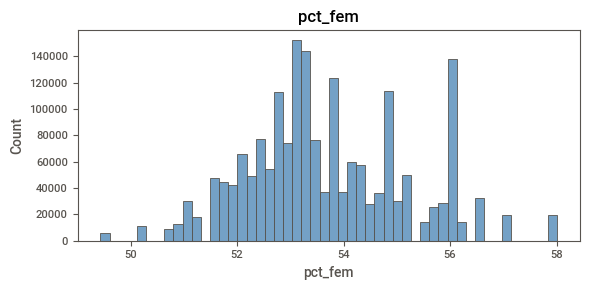

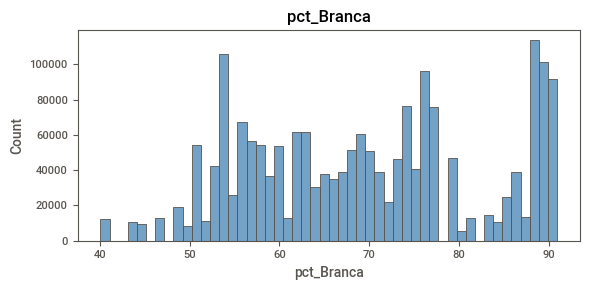

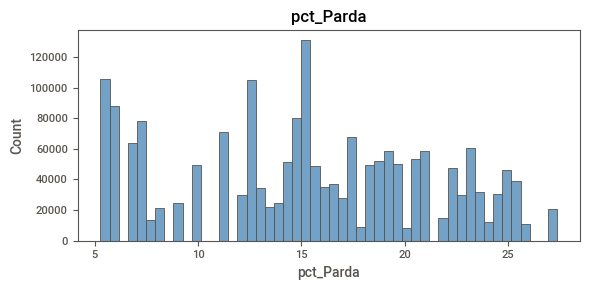

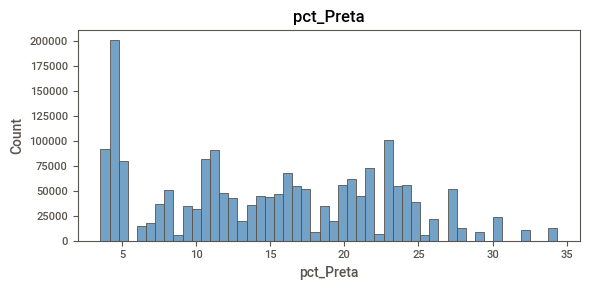

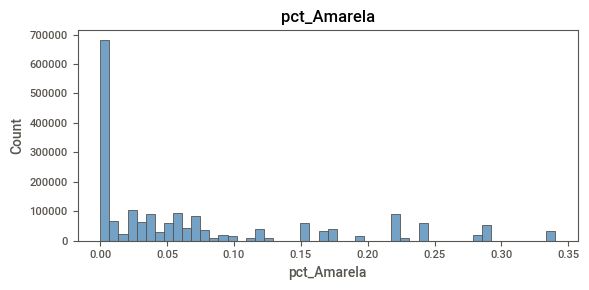

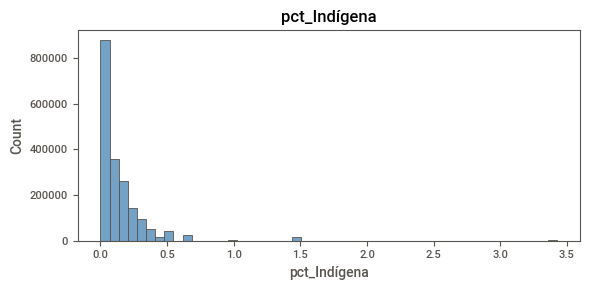

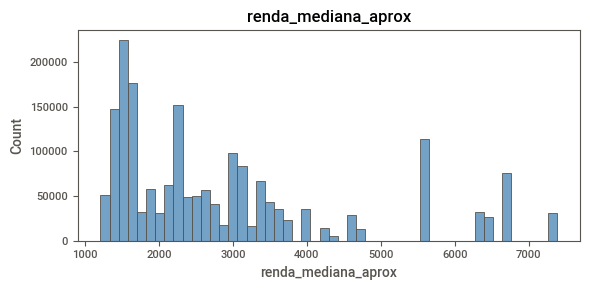

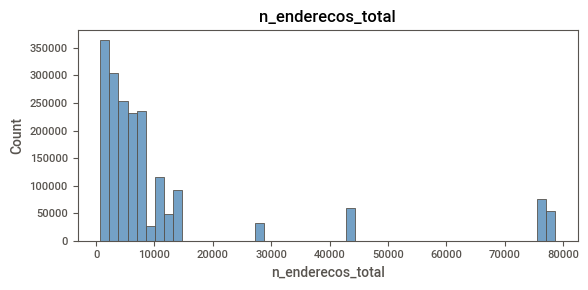

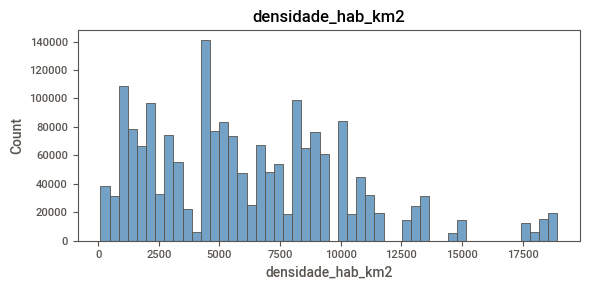

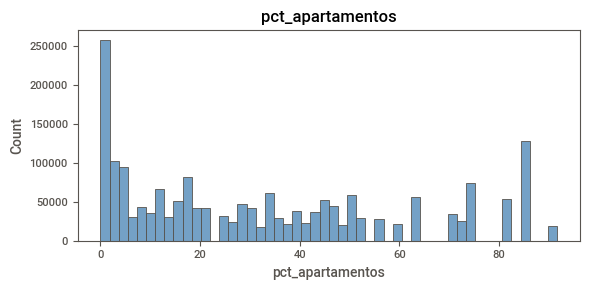

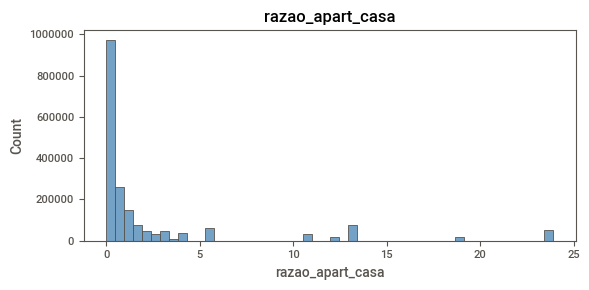

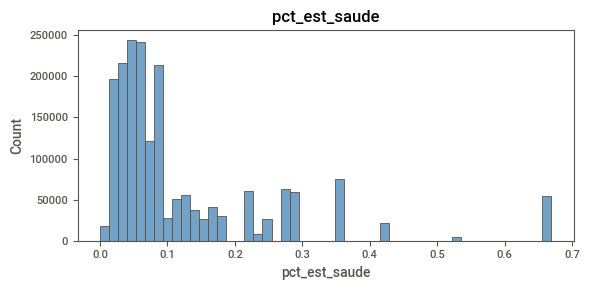

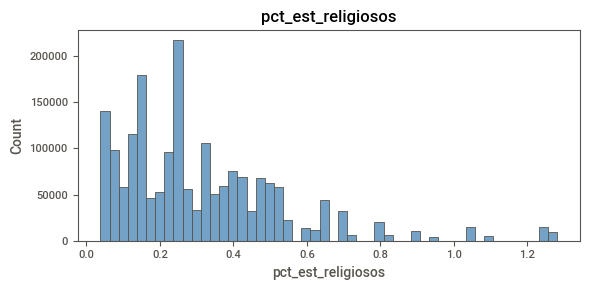

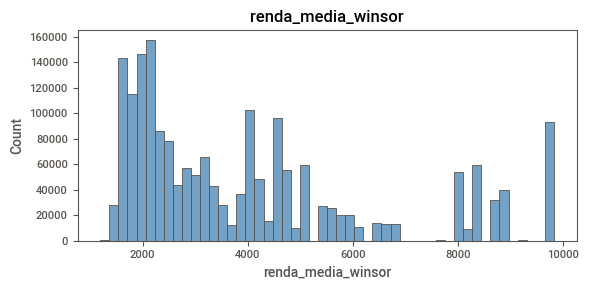

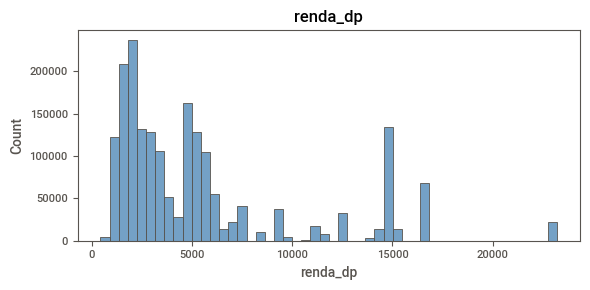

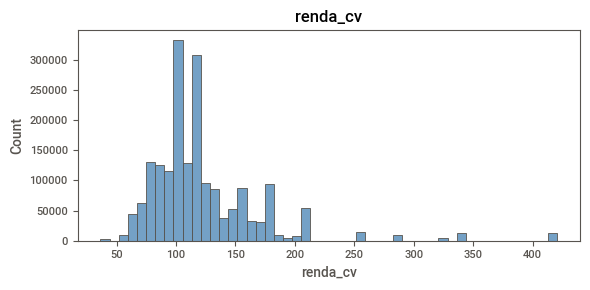

In [19]:
for col in numeric_cols:
    fig, ax = plt.subplots(figsize=(6, 3))
    sns.histplot(df[col].dropna(), bins=50, ax=ax, color='steelblue')
    ax.set_title(col)
    plt.tight_layout()
    plt.show()

## 8. Variáveis categóricas

Top 20 categorias mais frequentes por coluna (ignora colunas com cardinalidade muito alta, tipo IDs).

censo_unidade_saude: 133 valores únicos
coordenadoria_saude: 4 valores únicos


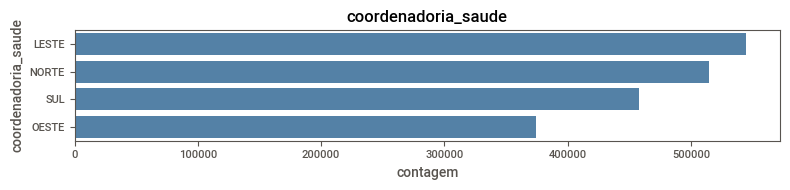

distrito_sanitario: 18 valores únicos


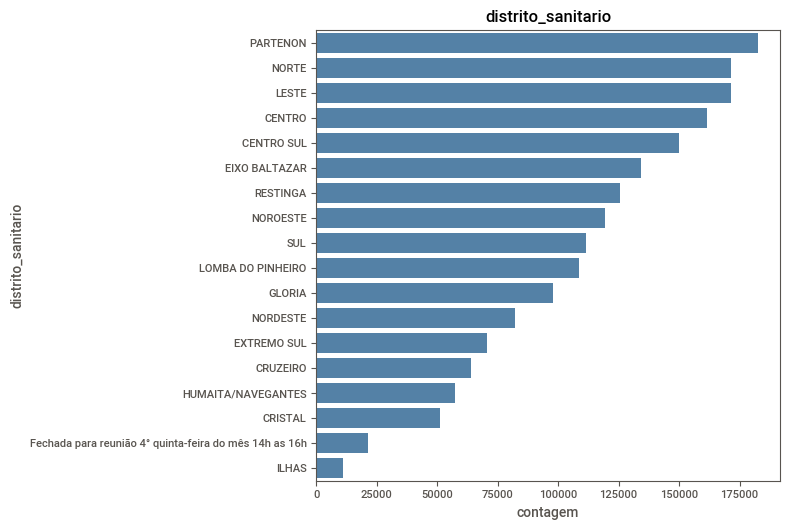

flag_renda_suspeita: 1 valores únicos


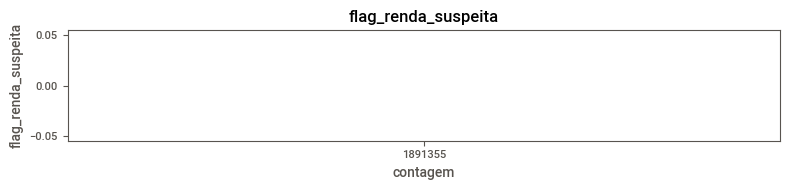

CID_ajustada: 1786 valores únicos


In [20]:
MAX_CARDINALITY = 50

for col in categorical_cols:
    n_unique = df[col].nunique(dropna=True)
    print(f"{col}: {n_unique} valores únicos")
    if n_unique == 0 or n_unique > MAX_CARDINALITY:
        continue
    top = df[col].value_counts(dropna=True).head(20)
    fig, ax = plt.subplots(figsize=(8, max(2, len(top) * 0.3)))
    sns.barplot(x=top.values, y=top.index, ax=ax, color='steelblue')
    ax.set_title(col)
    ax.set_xlabel('contagem')
    plt.tight_layout()
    plt.show()

## 8.1 Remoção de colunas adicionais e ajuste do CID

Remove `regiaosaudesolicitante`, `coordenadoriasolicitante`, `tipoconsulta` e `municipiosolicitante`, e cria `cid_ajustada` com os 3 primeiros caracteres de `cid` (categoria do CID, sem subcategoria).

In [21]:
print(df.columns.tolist())

['ANO_SOLICITACAO', 'IDSOLICITACAO', 'SITUACAOSOLICITACAO', 'DATA_SOLICITACAO', 'CORREGULADOR', 'DIASFILAESPERA', 'COMPLEXIDADE', 'ESPECIALIDADE', 'ESPECIALIDADEMAE', 'CID', 'IDPACIENTE', 'MUNICIPIO_RESIDENCIA', 'IDADE', 'CNES_SOLICITANTE', 'UNIDADESOLICITANTE', 'SITUACAOAGENDA', 'DATAHORA_CONSULTA', 'CNESEXECUTANTE', 'UNIDADEEXECUTANTE', 'MUNICIPIO_EXECUTANTE', 'STATUSREGIONALIZACAO', 'CENTRALREGULACAO', 'CENTRALREGULACAOORIGEM', 'POSSUIUNIDADEINDICADA', 'REGISTROAGENDA', 'DESFECHO_CONSULTA', 'censo_unidade_saude', 'População Alocada à US', 'Favela/Comunidade', 'Não especial', 'area_km2_ponderada', 'taxa_alf_geral', 'pct_fem', 'pct_Branca', 'pct_Parda', 'pct_Preta', 'pct_Amarela', 'pct_Indígena', 'renda_mediana_aprox', 'coordenadoria_saude', 'distrito_sanitario', 'n_enderecos_total', 'densidade_hab_km2', 'pct_apartamentos', 'razao_apart_casa', 'pct_est_saude', 'pct_est_religiosos', 'renda_media_winsor', 'renda_dp', 'renda_cv', 'flag_renda_suspeita', 'CID_ajustada']


In [22]:
DROP_COLS_2 = [
    'regiaosaudesolicitante',
    'coordenadoriasolicitante',
    'tipoconsulta',
    'municipiosolicitante',
]
df = df.drop(columns=DROP_COLS_2, errors='ignore')

# cid_ajustada: categoria do CID (3 primeiros caracteres), sem a subcategoria
df['CID_ajustada  '] = df['CID'].astype(str).str[:3]

categorical_cols = [c for c in categorical_cols if c not in DROP_COLS_2] + ['cid_ajustada']

df.shape

(1912556, 53)

## 8.2 Análise bivariada: origem/central de regulação e regionalização x complexidade

Cruzamento de `centralregulacaoorigem`, `centralregulacao` e `statusregionalizacao` com `complexidade`: tabela de contingência (contagem e % por linha), teste qui-quadrado de associação e gráfico de barras empilhadas.

In [23]:
'print(df.columns.tolist())'

'print(df.columns.tolist())'

In [24]:
from scipy.stats import chi2_contingency

BIVAR_COLS = ['centralregulacaoorigem', 'centralregulacao', 'statusregionalizacao']

for col in BIVAR_COLS:
    if col not in df.columns:
        print(f'{col} não encontrada no dataframe.\n')
        continue

    sub = df[[col, 'complexidade']].dropna()
    print(f'=== {col} x complexidade ===')
    print(f'n = {len(sub):,} (de {len(df):,} linhas; {len(df) - len(sub):,} descartadas por valor ausente)')

    if sub.empty:
        print('Sem dados não-nulos para cruzar.\n')
        continue

    ct = pd.crosstab(sub[col], sub['complexidade'])
    ct_pct = pd.crosstab(sub[col], sub['complexidade'], normalize='index') * 100

    display(ct)
    display(ct_pct.round(1))

    if ct.shape[0] > 1 and ct.shape[1] > 1:
        chi2, p, dof, _ = chi2_contingency(ct)
        print(f'Qui-quadrado: {chi2:.2f} | p-valor: {p:.4g} | gl: {dof}')
    else:
        print('Variação insuficiente para teste qui-quadrado.')

    fig, ax = plt.subplots(figsize=(8, max(2, len(ct) * 0.4)))
    ct_pct.plot(kind='barh', stacked=True, ax=ax, colormap='Blues')
    ax.set_xlabel('% dentro da categoria')
    ax.set_title(f'{col} x complexidade')
    ax.legend(title='complexidade', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
    print()

centralregulacaoorigem não encontrada no dataframe.

centralregulacao não encontrada no dataframe.

statusregionalizacao não encontrada no dataframe.



## 9. Análise temporal (2018-2025)

Usa a primeira coluna de data detectada automaticamente. Troque `DATE_COL` manualmente se quiser usar outra.

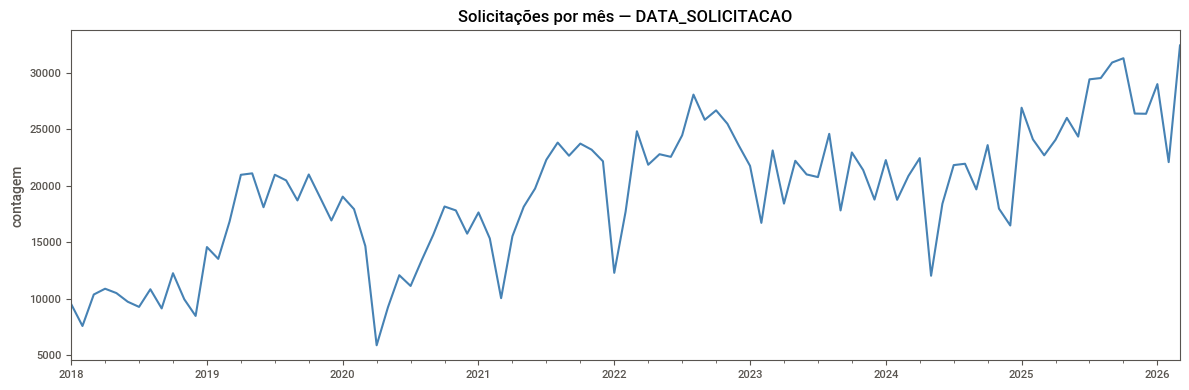

In [25]:
DATE_COL = date_cols[0] if date_cols else None

if DATE_COL:
    ts = df.set_index(DATE_COL).resample('MS').size()
    fig, ax = plt.subplots(figsize=(12, 4))
    ts.plot(ax=ax, color='steelblue')
    ax.set_title(f'Solicitações por mês — {DATE_COL}')
    ax.set_xlabel('')
    ax.set_ylabel('contagem')
    plt.tight_layout()
    plt.show()
else:
    print('Nenhuma coluna de data foi detectada automaticamente. Ajuste DATE_COL manualmente.')

## 10. Correlação entre variáveis numéricas

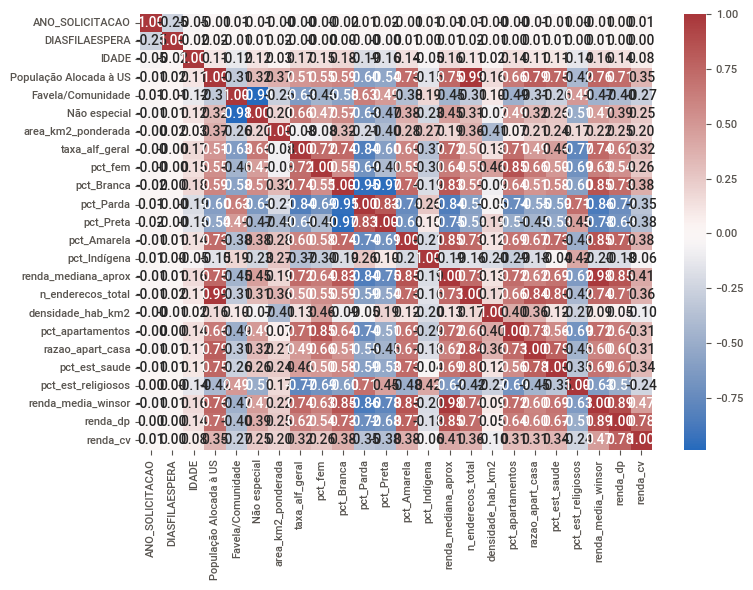

In [26]:
if len(numeric_cols) > 1:
    corr = df[numeric_cols].corr()
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', center=0, ax=ax)
    plt.tight_layout()
    plt.show()
else:
    print('Colunas numéricas insuficientes para matriz de correlação.')